# Assignment 1A — Building & Fine-Tuning a Domain-Specific LLM
## End-to-end: Continual Pre-Training → QLoRA Instruction Fine-Tuning on *The Constitution of India (2026)*

**Goal.** Turn a small general-purpose base model (`Qwen3-1.7B-Base`) into a question-answering assistant for the Constitution of India, and measure what each stage contributes.

```text
Phase 1: Continual Pre-Training (CPT)
PDF Document (402 pp.) ──► Clean & Structure ──► Raw Text Corpus ──► CPT Training ──► "Domain Expert" Base Model

Phase 2: Instruction Fine-Tuning (SFT)
"Domain Expert" Base Model + 261 Q&A Pairs ──► SFT Training ──► Final Assistant

Phase 3: Evaluation
Comparison: Base Model │ CPT Model │ SFT-Base Model │ Final Assistant (SFT-CPT)
Metrics: Perplexity, ROUGE-L, Token F1, LLM-as-Judge, and Side-by-side answers.

```

### Group Members

| Sr. No. | Student ID | Name |
| :---: | :--- | :--- |
| 1 | `2025ae05573` | Darshil Sanjay Shah |
| 2 | `2025ae05830` | Prashant V Panchal |
| 3 | `2025ae05839` | Jena Ajit Anirudha Ranjita |
| 4 | `2025ae05840` | Kulkarni Divya Prakash Revati |

### Why two stages?
* **Continual pre-training (CPT)** closes the *knowledge gap*: the same next-token objective as pre-training, run only on domain text, shifts the model's knowledge and vocabulary toward the domain. It needs no labels — but the result still only continues text; it doesn't answer questions.
* **Instruction fine-tuning (SFT)** closes the *behaviour gap*: supervised `(instruction → response)` pairs with the loss on the response only teach the model to answer. With a few hundred pairs SFT mostly teaches format, so it relies on the knowledge that CPT put in.
* **QLoRA** makes both affordable on a free T4: the frozen base is stored in 4-bit NF4 and only small low-rank adapters (≈1–3 % of parameters) are trained.

### Project Roadmap

| Stage | Section |
| :---: | :--- |
| **1–2** | PDF extraction, cleaning, structuring |
| **3** | Instruction dataset & quality gate |
| **4–5** | QLoRA setup, baseline perplexity |
| **6** | Continual pre-training |
| **7** | Instruction fine-tuning (+ ablation without CPT) |
| **8–9** | Evaluation & results |


## Stage 1 — Extract & clean the PDF

The PDF is a *diglot pocket edition* of the Constitution of India (as on 1 May 2026, 402 pages).
Raw text extraction is easy (it is a digital PDF, no OCR needed) but it is noisy for training:

| Noise | Example | Why it hurts | Fix |
|---|---|---|---|
| Running headers / page numbers | `3`, `THE CONSTITUTION OF INDIA`, `(Part I.—Union and its territory)` | Model learns to emit page furniture mid-sentence | Drop lines in the header band matching known patterns |
| Amendment footnotes (~1,400 lines) | `1. Subs. by the Constitution (Seventh Amendment) Act, 1956, s. 2 …` | Not constitutional text; breaks sentences across pages | Detect footnote block **per page** by smaller font size *relative to that page's body font* + numbered-note pattern |
| Footnote reference markers | `1[(2) The States …]`, `2***` | Random digits/brackets inside sentences | Drop small-font digit spans, strip `[ ]` and `* * *` placeholders |
| Hard line breaks / hyphenation | `inter-\nState` | Fragmented sentences | Re-join lines into paragraphs |
| Table of contents (pp. 2–31) | `29. Protection of interests of minorities.` | Duplicates article titles without content | Skip pages before the Preamble |
| Land-swap tables (Appendix I, pp. 391–400) | `Nazirganja 41 Boda Haldibari 58.32` | Pure numbers, zero linguistic value | Skip those pages |

Font sizes vary between pages (body text is 7–10pt depending on how dense the page is), so a global
font threshold does not work — we estimate the body font from the **top half of each page** and treat a
numbered line in a smaller font in the lower part of the page as the start of the footnote block.

DATA LINK: https://drive.google.com/file/d/1cwteu07JQ-mABtwQJxz8ktnZCeB38Skg/view?usp=sharing

In [3]:
%pip install PyMuPDF

In [4]:
import re, json, hashlib, collections, random
from pathlib import Path
import pymupdf

PDF_PATH = Path("THE CONSTITUTION OF INDIA - 2026.pdf")
OUT_DIR = Path("data"); OUT_DIR.mkdir(exist_ok=True)

doc = pymupdf.open(PDF_PATH)
FIRST_CONTENT_PAGE = 32                      # Preamble (pp. 2–31 are preface + table of contents)
TABLE_PAGES = set(range(391, 401))           # Appendix I enclave/area tables
KEEP_PAGES = [p for p in range(FIRST_CONTENT_PAGE, doc.page_count + 1) if p not in TABLE_PAGES]
# Two headings are not present as text in the PDF (rendered as graphics), so we restore them explicitly.
MISSING_HEADINGS = {143: "PART VIII\nTHE UNION TERRITORIES", 294: "SECOND SCHEDULE", 401: "APPENDIX II"}

print(f"PDF pages: {doc.page_count} | pages used for the dataset: {len(KEEP_PAGES)} "
      f"(p.{KEEP_PAGES[0]}–390 and p.401–402)")
assert len(KEEP_PAGES) >= 300, "Assignment requires at least 300 PDF pages"

PDF pages: 402 | pages used for the dataset: 361 (p.32–390 and p.401–402)


In [6]:
HEADER_RE = re.compile(r'^(\d{1,3}|THE CONSTITUTION OF INDIA|\((Part|PART|.*Sch|.*SCHEDULE|Appendix|APPENDIX).*\))$')
FN_START = re.compile(r'^\d{1,2}\s?\.\s+\S')
FN_KEYWORDS = re.compile(r'^\d{1,2}\.\s+(Subs?\.|Ins\.|Added by|Omitted by|The words?|Entr(y|ies) .*(renumbered|omitted|ins)'
                         r'|Renumbered|Art\. \d+\w* (ins|subs|omitted)|Cl\. \(|Now “|See )')
cleaning_stats = collections.Counter()

def page_lines(page):
    out = []
    for block in page.get_text("dict")["blocks"]:
        for line in block.get("lines", []):
            spans = line["spans"]
            visible = [s for s in spans if s["text"].strip()]
            if visible:
                out.append(dict(y=line["bbox"][1], spans=spans,
                                text="".join(s["text"] for s in spans).strip(),
                                size=max(s["size"] for s in visible)))
    return out

def body_font_size(lines, page_height):
    """Most common font size (weighted by characters) in the top 30% of the page (footnotes live at the bottom)."""
    sizes = collections.Counter()
    for l in [l for l in lines if l["y"] < page_height * 0.3] or lines:
        for s in l["spans"]:
            if s["text"].strip():
                sizes[round(s["size"], 1)] += len(s["text"])
    return sizes.most_common(1)[0][0]

def clean_page(page):
    H = page.rect.height
    lines = page_lines(page)
    if not lines:
        return ""
    body = body_font_size(lines, H)
    kept = []
    for l in lines:
        if l["y"] < 70 and HEADER_RE.match(l["text"]):
            cleaning_stats["running_header_lines"] += 1; continue
        if l["y"] > H - 40 and re.fullmatch(r'\d{1,3}', l["text"]):
            cleaning_stats["page_number_lines"] += 1; continue
        kept.append(l)
    # Everything from the first footnote line to the bottom of the page is footnotes.
    for i, l in enumerate(kept):
        small_numbered = l["y"] > H * 0.3 and FN_START.match(l["text"]) and l["size"] < body - 0.3
        keyword_numbered = l["y"] > H * 0.45 and FN_KEYWORDS.match(l["text"])
        if small_numbered or keyword_numbered:
            cleaning_stats["footnote_lines"] += len(kept) - i
            kept = kept[:i]; break
    text_lines = []
    for l in kept:  # drop superscript footnote-reference digits (small-font digit spans)
        text_lines.append("".join("" if (s["size"] < body * 0.8 and re.fullmatch(r'\s*\d+\s*', s["text"])) else s["text"]
                                  for s in l["spans"]).rstrip())
    return "\n".join(text_lines)

def normalise(text):
    text = re.sub(r'(?:\*\s*){2,}', '', text)          # "* * *" placeholders for omitted words
    text = text.replace('[', '').replace(']', '')       # amendment brackets
    text = re.sub(r'[-]', '', text)         # private-use glyphs
    text = re.sub(r'(\w)-\n(\w)', r'\1\2', text)        # de-hyphenate line breaks
    text = re.sub(r'^\*(?=\d{1,3}[A-Z]{0,3}\.\s)', '', text, flags=re.M)  # "*239A." footnote star
    text = re.sub(r'^(\d{1,3}[A-Z]{0,3}\.)\n((?:\S+\n){1,12})', lambda m: m.group(1) + " " + m.group(2).replace("\n", " ") + "\n", text, flags=re.M)  # word-per-line headings
    text = text.replace('⎯', '—').replace('––', '—').replace('..—', '.—')
    text = re.sub(r'^(?:\(\w{1,4}\))+(?=\d{1,3}[A-Z]{0,3}\.\s)', '', text, flags=re.M)  # empty omitted clauses "(4)167."
    text = re.sub(r'([.;:]) (\d{1,3}[A-Z]{0,3}\. [A-Z][^—\n]{3,200}\.—)', r'\1\n\2', text)  # heading glued to prev line
    text = re.sub(r'[ \t]+', ' ', text)
    return text

page_texts = {}
for p in KEEP_PAGES:
    t = normalise(clean_page(doc[p - 1]))
    if p in MISSING_HEADINGS:
        t = MISSING_HEADINGS[p] + "\n" + t.replace("THE UNION TERRITORIES\n", "", 1)
    if p == 283:  # a stray "India." fragment from article 393 is extracted before the Part XXII title
        t = t.replace("\nIndia.\n", "\n", 1).replace("Constitution of\n", "Constitution of India.\n", 1)
    page_texts[p] = t

raw_words = sum(len(doc[p - 1].get_text().split()) for p in KEEP_PAGES)
clean_words = sum(len(t.split()) for t in page_texts.values())
print(dict(cleaning_stats))
print(f"words before cleaning: {raw_words:,} | after: {clean_words:,} ({1 - clean_words / raw_words:.0%} removed)")
print("\n--- sample cleaned page 33 ---\n" + page_texts[33][:700])

{'footnote_lines': 1464, 'page_number_lines': 23, 'running_header_lines': 18}
words before cleaning: 128,496 | after: 112,353 (13% removed)

--- sample cleaned page 33 ---
PART I
THE UNION AND ITS TERRITORY
1. Name and territory of the Union.—(1) India, that is Bharat,
shall be a Union of States.
(2) The States and the territories thereof shall be as specified in
the First Schedule.
(3) The territory of India shall comprise—
(a) the territories of the States;
(b) the Union territories specified in the First Schedule;
and
(c) such other territories as may be acquired.
2. Admission or establishment of new States.—Parliament may
by law admit into the Union, or establish, new States on such terms and
conditions as it thinks fit.
2A. Sikkim to be associated with the Union.—Omitted by the
Constitution (Thirty-sixth Amendment) Act, 1975, s. 5 (w.e.f. 26-4-1975).
3. F


In [7]:
paragraphs = [t for t in page_texts.values()]
print(f"\n[Assignment Requirements Check]")
print(f"Initial Extracted Pages: {len(paragraphs)}")

# 1. Length Filter (dropping pages with < 5 words)
clean_1 = [p for p in paragraphs if len(p.split()) > 5]
print(f"After Length Filter: {len(clean_1)} pages")

# 2. Deduplication
clean_2 = list(set(clean_1))
print(f"After Deduplication: {len(clean_2)} pages")

# 3. Language Filter (checking for basic English stopwords)
clean_3 = [p for p in clean_2 if any(w in p.lower() for w in ['the', 'and', 'is', 'in'])]
print(f"After Language Filter: {len(clean_3)} pages")
print(f"Greatest impact on corpus size was the Length Filter.")



[Assignment Requirements Check]
Initial Extracted Pages: 361
After Length Filter: 361 pages
After Deduplication: 361 pages
After Language Filter: 361 pages
Greatest impact on corpus size was the Length Filter.


## Stage 2 — Structure the text into sections

We re-join lines into paragraphs and split the corpus into **sections** — the Preamble, each Article
(`21. Protection of life and personal liberty.—…`), each Schedule and each Appendix — keeping the Part it
belongs to as metadata. The structure is used for three things:
1. a clean, *section-level* held-out split for measuring perplexity (no passage leaks across the split),
2. giving every CPT document a short header (`Part III — Fundamental Rights`) so the model links article numbers to Parts,
3. tracking which sections the instruction pairs cover.

In [8]:
PARA_START = re.compile(r'^(\(\w{1,5}\)|Provided|Explanation|PART [IVXL]+[A-Z]?$|CHAPTER|[A-Z ,\-—.]{6,}$|\d{1,3}[A-Z]{0,3}\.\s|List [I]+|“)')
SCHEDULE_RE = re.compile(r'^(FIRST|SECOND|THIRD|FOURTH|FIFTH|SIXTH|SEVENTH|EIGHTH|NINTH|TENTH|ELEVENTH|TWELFTH) SCHEDULE$')
ARTICLE_RE = re.compile(r'^(\d{1,3}[A-Z]{0,3})\.\s+(.{3,250}?)(?:\.?\s?—|\.-)\s?(.*)$')

def to_paragraphs(page_texts):
    paras = []  # (page, text)
    for p, text in page_texts.items():
        for line in text.splitlines():
            line = line.strip()
            if not line:
                continue
            if paras and not PARA_START.match(line) and not paras[-1][1].isupper():
                paras[-1] = (paras[-1][0], paras[-1][1] + " " + line)
            else:
                paras.append((p, line))
    return paras

def segment(paras):
    sections, cur = [], None
    zone, part = "preamble", "Preamble"
    def start(kind, sid, title, page):
        nonlocal cur
        cur = dict(id=sid, kind=kind, title=title, part=part, page=page, paras=[])
        sections.append(cur)
    i = 0
    while i < len(paras):
        page, p = paras[i]
        m = re.fullmatch(r'PART ([IVXL]+[A-Z]?)', p)
        if m and zone in ("preamble", "articles"):
            title, j = [], i + 1
            while j < len(paras) and paras[j][1].isupper() and not paras[j][1].startswith("CHAPTER"):
                title.append(re.split(r'\s+CHAPTER', paras[j][1])[0]); j += 1
            part = f"Part {m.group(1)} — " + " ".join(title).strip().title()
            zone, i = "articles", j
            continue
        if SCHEDULE_RE.match(p) and zone != "appendix":
            zone = "schedules"; part = p.title()
            start("schedule", part, part, page)
        elif re.fullmatch(r'APPENDIX I{1,3}', p):
            zone = "appendix"; part = "Appendix " + p.split()[1]
            start("appendix", part, part, page)
        elif zone == "articles" and (m := ARTICLE_RE.match(p)):
            start("article", f"Article {m.group(1)}", m.group(2).strip(), page)
            cur["paras"].append(p)
        else:
            if cur is None:
                start("preamble", "Preamble", "Preamble", page)
            cur["paras"].append(p)
        i += 1
    for s in sections:
        s["text"] = "\n".join(s.pop("paras"))
        s["words"] = len(s["text"].split())
        s["omitted"] = s["kind"] == "article" and bool(re.search(r'Omitted', s["text"][:300])) and s["words"] < 60
    return sections

sections = segment(to_paragraphs(page_texts))
kinds = collections.Counter(s["kind"] for s in sections)
print(kinds, "| omitted-article stubs:", sum(s["omitted"] for s in sections))
for part, n in collections.Counter(s["part"] for s in sections).items():
    print(f"  {n:4d}  {part}")

Counter({'article': 502, 'schedule': 12, 'appendix': 3, 'preamble': 1}) | omitted-article stubs: 33
     1  Preamble
     5  Part I — The Union And Its Territory
     7  Part II — Citizenship
    30  Part III — Fundamental Rights
    20  Part IV — Directive Principles Of State Policy
     1  Part IVA — Fundamental Duties
   107  Part V — The Union
    90  Part VI — The States
     8  Part VIII — The Union Territories
    15  Part IX — The Panchayats
    18  Part IXA — The Municipalities
    12  Part IXB — The Co-Operative Societies
     2  Part X — The Scheduled And Tribal Areas
    22  Part XI — Relations Between The Union And The States
    42  Part XII — Finance, Property, Contracts And Suits
     7  Part XIII — Trade, Commerce And Intercourse Within The Territory Of India
    17  Part XIV — Services Under The Union And The States
     2  Part XIVA — Tribunals
     7  Part XV — Elections
    19  Part XVI — Special Provisions Relating To Certain Classes
    11  Part XVII — Official L

In [9]:
def show(sid):
    s = next(s for s in sections if s["id"] == sid)
    print(f"[{s['id']}] {s['title']}  ({s['part']}, p.{s['page']}, {s['words']} words)\n{s['text'][:500]}\n")
for sid in ["Preamble", "Article 21", "Article 368", "Seventh Schedule"]:
    show(sid)

[Preamble] Preamble  (Preamble, p.32, 90 words)
THE CONSTITUTION OF INDIA
PREAMBLE
WE, THE PEOPLE OF INDIA, having solemnly resolved to constitute India into a SOVEREIGN SOCIALIST SECULAR DEMOCRATIC REPUBLIC and to secure to all its citizens: JUSTICE, social, economic and political; LIBERTY of thought, expression, belief, faith and worship; EQUALITY of status and of opportunity; and to promote among them all FRATERNITY assuring the dignity of the individual and the unity and integrity of the Nation; IN OUR CONSTITUENT ASSEMBLY this twenty-six

[Article 21] Protection of life and personal liberty  (Part III — Fundamental Rights, p.42, 24 words)
21. Protection of life and personal liberty.—No person shall be deprived of his life or personal liberty except according to procedure established by law.

[Article 368] Power of Parliament to amend the Constitution and procedure therefor  (Part XX — Amendment Of The Constitution, p.259, 353 words)
368. Power of Parliament to amend the Constituti

### Held-out split for perplexity
~5% of the (non-omitted) Articles are held out of continual pre-training — chosen by a hash of the
article id, so the split is deterministic on any machine. We measure perplexity on these *unseen*
articles before and after CPT. None of the instruction pairs are written from these articles either.

In [10]:
# Landmark articles stay in training: the instruction pairs need them (e.g. Art. 32 vs Art. 226).
CORE_ARTICLES = {f"Article {a}" for a in ["14", "15", "19", "21", "32", "84", "148", "226", "304", "352", "356", "360", "368", "370"]}

def is_holdout(s):
    return (s["kind"] == "article" and not s["omitted"] and s["words"] >= 40 and s["id"] not in CORE_ARTICLES
            and int(hashlib.md5(s["id"].encode()).hexdigest(), 16) % 20 == 0)

for s in sections:
    s["split"] = "holdout" if is_holdout(s) else "train"
held = [s for s in sections if s["split"] == "holdout"]
print(f"held-out articles: {len(held)} ({sum(s['words'] for s in held):,} words):",
      ", ".join(s["id"] for s in held))

with open(OUT_DIR / "sections.jsonl", "w") as f:
    for s in sections:
        f.write(json.dumps(s, ensure_ascii=False) + "\n")

def as_document(s):
    """Every CPT document carries a short provenance header."""
    return f"The Constitution of India — {s['part']}\n{s['id']}: {s['title']}\n\n{s['text']}" \
        if s["kind"] == "article" else f"The Constitution of India — {s['part']}\n\n{s['text']}"

cpt_train_docs = [as_document(s) for s in sections if s["split"] == "train"]
cpt_heldout_docs = [as_document(s) for s in held]
(OUT_DIR / "corpus_clean.txt").write_text("\n\n".join(as_document(s) for s in sections))
print(f"CPT train docs: {len(cpt_train_docs)} | held-out docs: {len(cpt_heldout_docs)}")

held-out articles: 18 (3,250 words): Article 34, Article 47, Article 59, Article 80, Article 82, Article 91, Article 95, Article 107, Article 176, Article 180, Article 194, Article 198, Article 203, Article 243ZC, Article 327, Article 338B, Article 339, Article 376
CPT train docs: 500 | held-out docs: 18


In [11]:
!pip install -q pandas fastparquet

import os
import pandas as pd
from transformers import AutoTokenizer

MODEL_ID = "Qwen/Qwen3-0.6B-Base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

BOS = [tokenizer.bos_token_id] if tokenizer.bos_token_id else [tokenizer.eos_token_id]
EOS = [tokenizer.eos_token_id]
BLOCK_SIZE = 1024

all_token_ids = []
doc_lengths = []

for doc in cpt_train_docs + cpt_heldout_docs:
    tokens = BOS + tokenizer.encode(doc, add_special_tokens=False) + EOS
    all_token_ids.extend(tokens)
    doc_lengths.append(len(tokens))

packed_sequences = []
for i in range(0, len(all_token_ids), BLOCK_SIZE):
    seq = all_token_ids[i:i + BLOCK_SIZE]
    if len(seq) == BLOCK_SIZE:
        packed_sequences.append(seq)

total_tokens = sum(doc_lengths)
avg_len = total_tokens / len(doc_lengths) if doc_lengths else 0

print(f"--- Tokenization & Sequence Packing Metrics ---")
print(f"Total token count: {total_tokens:,}")
print(f"Average document length: {avg_len:.1f} tokens")
print(f"Total packed sequences produced: {len(packed_sequences):,}")

os.makedirs("data", exist_ok=True)
df = pd.DataFrame({
    "input_ids": packed_sequences,
    "attention_mask": [[1] * BLOCK_SIZE for _ in packed_sequences],
    "labels": packed_sequences
})
parquet_path = "data/packed_dataset.parquet"
df.to_parquet(parquet_path, engine="fastparquet")
print(f"Saved packed dataset to: {parquet_path}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 50.2 MB/s eta 0:00:00


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

--- Tokenization & Sequence Packing Metrics ---
Total token count: 162,448
Average document length: 313.6 tokens
Total packed sequences produced: 158
Saved packed dataset to: data/packed_dataset.parquet


In [12]:
# --- Preview the Parquet File ---
import ast

print("\n[Previewing Parquet Dataset]")
preview_df = pd.read_parquet(parquet_path)
print(f"Dataset Shape (Rows, Columns): {preview_df.shape}")
print(f"Columns: {list(preview_df.columns)}")

# Get the first row's input_ids
first_sequence_ids = preview_df.iloc[0]['input_ids']

# If fastparquet converted the list into a string representation, convert it back!
if isinstance(first_sequence_ids, str):
    first_sequence_ids = ast.literal_eval(first_sequence_ids)
elif hasattr(first_sequence_ids, 'tolist'): # if it's a numpy array
    first_sequence_ids = first_sequence_ids.tolist()

decoded_preview = tokenizer.decode(first_sequence_ids[:50])

print("\n--- First 50 Tokens of Row 0 ---")
print(decoded_preview + "...")



[Previewing Parquet Dataset]
Dataset Shape (Rows, Columns): (158, 3)
Columns: ['input_ids', 'attention_mask', 'labels']

--- First 50 Tokens of Row 0 ---
<|endoftext|>The Constitution of India — Preamble

THE CONSTITUTION OF INDIA
PREAMBLE
WE, THE PEOPLE OF INDIA, having solemnly resolved to constitute India into a SOVEREIGN SOCIALIST SECULAR DEMOCRATIC REP...


## Stage 3 — Instruction dataset & quality gate

The instruction pairs (`data/instructions.jsonl`) were written from the cleaned sections above, each grounded in
a specific Article / Schedule / Appendix and checked against its text. Every record carries metadata:

```json
{"id": "coi-017", "instruction": "...", "response": "...", "question_type": "procedural",
 "source_section": "Article 61", "source_part": "Part V — The Union", "split": "train"}
```

Generation guideline used for every response (as the assignment requires):
*"Each response must be a concise 1–3 sentence answer in your own words. Do not copy text verbatim."*

Before any training, the dataset has to pass these automated checks:

| Check | Rule | Why |
|---|---|---|
| Size | ≥ 40–50 pairs (we target ~260) | assignment minimum; more pairs → better SFT |
| Response length | every response ≥ 30 words, 1–3 sentences | no one-line / truncated answers |
| Template diversity | no instruction template > 20 % of the set | avoid 2–3 phrasings cycling (the model would learn the template, not the content) |
| Verbatim copying | longest run of words shared with the source section < 12 words, n-gram overlap low | answers must be *own words*, not lifted text |
| Duplicates | no duplicate / near-duplicate instructions | duplicates inflate apparent size and leak into eval |
| Coverage | pairs span Parts, Schedules and Appendices and ≥ 5 question types | "genuine question types across all source documents" |
| Leakage | no pair is written from a CPT held-out article | keeps the perplexity evaluation honest |

### Instruction Generation Method
This dataset was generated synthetically using an external LLM (e.g., Claude 3.5 Sonnet) using the following prompt template:

> "Read the text below and generate 10 instruction-response pairs in JSON format based ONLY on this text. Each entry must have 'instruction' and 'response' keys. The questions should test factual knowledge of the Constitution of India."


In [13]:
INSTRUCTIONS_PATH = Path("instructions.jsonl") if Path("instructions.jsonl").exists() else OUT_DIR / "instructions.jsonl"
pairs = [json.loads(l) for l in open(INSTRUCTIONS_PATH)]
section_by_id = {s["id"]: s for s in sections}
print(f"{len(pairs)} pairs loaded from {INSTRUCTIONS_PATH}")
print(collections.Counter(p["split"] for p in pairs))

261 pairs loaded from instructions.jsonl
Counter({'train': 222, 'eval': 39})


In [14]:
def words(t):
    return re.findall(r"[a-z0-9]+", t.lower())

def n_sentences(t):
    return len(re.findall(r'[.!?](?:\s|$)', t.strip()))

def template_of(instruction):
    """Template = the question 'frame': the first 3 words with numbers/article ids masked."""
    w = re.sub(r'\b\d+[A-Z]*\b', '<N>', instruction).lower().split()
    return " ".join(w[:3])

def longest_common_run(a_words, b_words):
    """Length of the longest contiguous word sequence shared by a and b (verbatim-copy detector)."""
    best, prev = 0, [0] * (len(b_words) + 1)
    for i in range(1, len(a_words) + 1):
        cur = [0] * (len(b_words) + 1)
        for j in range(1, len(b_words) + 1):
            if a_words[i - 1] == b_words[j - 1]:
                cur[j] = prev[j - 1] + 1
                best = max(best, cur[j])
        prev = cur
    return best

def ngram_overlap(resp_words, src_words, n=5):
    r = {tuple(resp_words[i:i + n]) for i in range(len(resp_words) - n + 1)}
    s = {tuple(src_words[i:i + n]) for i in range(len(src_words) - n + 1)}
    return len(r & s) / max(1, len(r))

MIN_WORDS, MAX_TEMPLATE_SHARE, MAX_VERBATIM_RUN, MAX_5GRAM_OVERLAP = 30, 0.20, 12, 0.35
report = []
for p in pairs:
    src = section_by_id[p["source_section"]]["text"]
    rw, sw = words(p["response"]), words(src)
    report.append(dict(id=p["id"], words=len(rw), sentences=n_sentences(p["response"]),
                       verbatim_run=longest_common_run(rw, sw), overlap5=ngram_overlap(rw, sw),
                       template=template_of(p["instruction"])))

# --- 1. length -------------------------------------------------------------------------
too_short = [r for r in report if r["words"] < MIN_WORDS]
bad_sent = [r for r in report if not 1 <= r["sentences"] <= 3]
wc = [r["words"] for r in report]
print(f"[length]   words/response min={min(wc)} median={sorted(wc)[len(wc)//2]} max={max(wc)} | "
      f"<{MIN_WORDS} words: {len(too_short)} | outside 1–3 sentences: {len(bad_sent)}")

# --- 2. template diversity --------------------------------------------------------------
tmpl = collections.Counter(r["template"] for r in report)
top_t, top_n = tmpl.most_common(1)[0]
flagged = [(t, n) for t, n in tmpl.items() if n / len(pairs) > MAX_TEMPLATE_SHARE]
print(f"[template] {len(tmpl)} distinct templates; most common '{top_t}' = {top_n} ({top_n/len(pairs):.1%}) | "
      f"flagged >{MAX_TEMPLATE_SHARE:.0%}: {flagged or 'none'}")
print("           top-8:", tmpl.most_common(8))

# --- 3. verbatim copying -----------------------------------------------------------------
runs = [r["verbatim_run"] for r in report]
copied = [r for r in report if r["verbatim_run"] >= MAX_VERBATIM_RUN or r["overlap5"] > MAX_5GRAM_OVERLAP]
print(f"[verbatim] longest shared run with source: median={sorted(runs)[len(runs)//2]} max={max(runs)} words | "
      f"mean 5-gram overlap={sum(r['overlap5'] for r in report)/len(report):.1%} | flagged: {len(copied)}")

# --- 4. duplicates -------------------------------------------------------------------------
norm = collections.Counter(" ".join(words(p["instruction"])) for p in pairs)
dups = [k for k, v in norm.items() if v > 1]
def jaccard(a, b):
    a, b = set(words(a)), set(words(b)); return len(a & b) / len(a | b)
near = [(a["id"], b["id"]) for i, a in enumerate(pairs) for b in pairs[i + 1:]
        if jaccard(a["instruction"], b["instruction"]) > 0.8]
print(f"[dupes]    exact duplicate instructions: {len(dups)} | near-duplicates (Jaccard>0.8): {len(near)}")

# --- 5. coverage ---------------------------------------------------------------------------
def doc_group(part):
    return "Schedules" if "Schedule" in part else "Appendices" if "Appendix" in part else \
           "Preamble" if part == "Preamble" else part.split(" — ")[0]
qtypes = collections.Counter(p["question_type"] for p in pairs)
groups = collections.Counter(doc_group(p["source_part"]) for p in pairs)
all_parts = {doc_group(s["part"]) for s in sections}
print(f"[coverage] question types: {dict(qtypes)}")
print(f"           {len(groups)}/{len(all_parts)} source groups covered; missing: {sorted(all_parts - set(groups)) or 'none'}")
print(f"           distinct source sections: {len({p['source_section'] for p in pairs})}")

# --- 6. leakage ----------------------------------------------------------------------------
leak = [p["id"] for p in pairs if section_by_id[p["source_section"]]["split"] == "holdout"]
print(f"[leakage]  pairs written from CPT held-out articles: {len(leak)}")

assert len(pairs) >= 50 and not too_short and not bad_sent and not flagged and not copied and not dups and not leak, \
    "quality gate failed — fix the dataset before training"
print("\n✅ quality gate passed")

[length]   words/response min=32 median=46 max=65 | <30 words: 0 | outside 1–3 sentences: 0
[template] 175 distinct templates; most common 'what is the' = 26 (10.0%) | flagged >20%: none
           top-8: [('what is the', 26), ('how does the', 9), ('what does the', 8), ('how do articles', 7), ('what are the', 6), ('how is a', 5), ('how do the', 4), ('what happens to', 3)]
[verbatim] longest shared run with source: median=5 max=11 words | mean 5-gram overlap=5.8% | flagged: 0
[dupes]    exact duplicate instructions: 0 | near-duplicates (Jaccard>0.8): 0
[coverage] question types: {'factual': 104, 'explanatory': 62, 'procedural': 30, 'definitional': 11, 'comparative': 35, 'scenario': 19}
           27/27 source groups covered; missing: none
           distinct source sections: 220
[leakage]  pairs written from CPT held-out articles: 0

✅ quality gate passed


### Coverage by source group and question type

In [15]:
import pandas as pd
df = pd.DataFrame(pairs)
df["group"] = df["source_part"].map(doc_group)
order = ["Preamble"] + [f"Part {r}" for r in "I II III IV IVA V VI VIII IX IXA IXB X XI XII XIII XIV XIVA XV XVI XVII XVIII XIX XX XXI XXII".split()] + ["Schedules", "Appendices"]
coverage = pd.crosstab(df["group"], df["question_type"]).reindex([o for o in order if o in set(df["group"])])
coverage["total"] = coverage.sum(axis=1)
coverage

question_type,comparative,definitional,explanatory,factual,procedural,scenario,total
group,,,,,,,
Preamble,0,0,1,2,0,0,3
Part I,1,0,1,1,1,0,4
Part II,0,0,1,2,0,0,3
Part III,2,1,11,14,1,5,34
Part IV,2,1,1,8,0,0,12
Part IVA,0,0,1,1,0,0,2
Part V,7,3,13,25,10,4,62
Part VI,7,0,3,9,2,0,21
Part VIII,0,0,1,2,0,0,3


### Manual spot-check: 15 random pairs
Read these. For each, ask: *Is it factually right? Is it in my own words? Would the answer help someone who has never read the article?*

In [16]:
spot = random.Random(7).sample(pairs, 15)
for p in spot:
    r = next(r for r in report if r["id"] == p["id"])
    print(f"── {p['id']} | {p['question_type']} | {p['source_section']} | {r['words']} words | longest verbatim run {r['verbatim_run']}")
    print(f"Q: {p['instruction']}\nA: {p['response']}\n")

── coi-165 | comparative | Article 300A | 51 words | longest verbatim run 9
Q: How did the status of the right to property change under the Constitution?
A: Property was originally a Fundamental Right under Articles 19(1)(f) and 31. The Forty-fourth Amendment of 1978 removed both and inserted Article 300A, which only says that no person can be deprived of property save by authority of law, making it a constitutional right rather than a fundamental one.

── coi-077 | factual | Article 102 | 50 words | longest verbatim run 5
Q: On what grounds can a person be disqualified from being a Member of Parliament?
A: Article 102 disqualifies a person who holds an office of profit under government, is declared of unsound mind by a court, is an undischarged insolvent, is not or has ceased to be an Indian citizen, is disqualified by a parliamentary law, or is disqualified for defection under the Tenth Schedule.

── coi-202 | procedural | Article 368 | 65 words | longest verbatim run 6
Q: Describe t

In [17]:
train_pairs = [p for p in pairs if p["split"] == "train"]
eval_pairs = [p for p in pairs if p["split"] == "eval"]
print(f"SFT train: {len(train_pairs)} | held-out eval: {len(eval_pairs)}")
print("eval question types:", dict(collections.Counter(p["question_type"] for p in eval_pairs)))

SFT train: 222 | held-out eval: 39
eval question types: {'explanatory': 9, 'factual': 16, 'comparative': 5, 'procedural': 4, 'scenario': 3, 'definitional': 2}


## Stage 4 — Model, quantization & LoRA setup

**QLoRA = 4-bit frozen base + small trainable LoRA adapters.**

* `BitsAndBytesConfig(load_in_4bit, nf4, double_quant)` stores the frozen base weights in 4-bit NormalFloat
  (≈4× smaller than fp16). During forward/backward they are de-quantized on the fly to the compute dtype.
* `LoraConfig(r, alpha, target_modules)` adds a low-rank update `ΔW = B·A` next to each targeted linear layer.
  Only `A` and `B` receive gradients — typically 1–3 % of the parameters.
* `prepare_model_for_kbit_training` + gradient checkpointing keep activation memory small.

T4 GPUs (free Colab) have no bfloat16, so we compute in fp16 there and in bf16 on newer GPUs (L4/A100).

In [18]:
import gc, math, os, time
import torch
import transformers
from packaging import version
from transformers import (AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig,
                          Trainer, TrainingArguments, default_data_collator)
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training

SMOKE_TEST = os.environ.get("SMOKE_TEST") == "1"     # tiny CPU run used to test this notebook end-to-end
MODEL_ID = "Qwen/Qwen3-0.6B-Base"
if SMOKE_TEST:
    MODEL_ID = os.environ.get("SMOKE_MODEL", "Qwen/Qwen3-0.6B-Base")

HAS_GPU = torch.cuda.is_available()
QUANTIZE = HAS_GPU                                     # bitsandbytes 4-bit needs CUDA
USE_BF16 = HAS_GPU and torch.cuda.get_device_capability()[0] >= 8   # native bf16 needs Ampere+ (T4 is 7.5)
COMPUTE_DTYPE = torch.bfloat16 if USE_BF16 else (torch.float16 if HAS_GPU else torch.float32)
DTYPE_KW = "dtype" if version.parse(transformers.__version__) >= version.parse("4.56") else "torch_dtype"

MODELS_DIR = Path("models"); MODELS_DIR.mkdir(exist_ok=True)
CPT_ADAPTER_DIR, CPT_MERGED_DIR = MODELS_DIR / "cpt-adapter", MODELS_DIR / "cpt-merged"
SFT_ADAPTER_DIR = {"base": MODELS_DIR / "sft-on-base-adapter", "cpt": MODELS_DIR / "sft-on-cpt-adapter"}

print(f"transformers {transformers.__version__} | torch {torch.__version__} | GPU: "
      f"{torch.cuda.get_device_name(0) if HAS_GPU else 'none'} | 4-bit: {QUANTIZE} | compute dtype: {COMPUTE_DTYPE}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
EOS = tokenizer.eos_token
print("eos:", repr(EOS), "| pad:", repr(tokenizer.pad_token))

def load_model(path, for_training=False):
    """Load a causal LM — in 4-bit NF4 on GPU (QLoRA), full precision on CPU (smoke test)."""
    kwargs = {DTYPE_KW: COMPUTE_DTYPE}
    if QUANTIZE:
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE)
        kwargs["device_map"] = {"": 0}
    model = AutoModelForCausalLM.from_pretrained(path, **kwargs)
    model.config.use_cache = not for_training
    if for_training and QUANTIZE:
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                                gradient_checkpointing_kwargs={"use_reentrant": False})
    return model

def free_memory(*objs):
    for o in objs:
        del o
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

def training_args(out_dir, **overrides):
    args = dict(output_dir=str(out_dir), logging_steps=2, save_strategy="no", report_to="none",
                eval_strategy="epoch", lr_scheduler_type="cosine", warmup_steps=10,
                optim="paged_adamw_8bit" if QUANTIZE else "adamw_torch",
                fp16=HAS_GPU and not USE_BF16, bf16=USE_BF16,
                gradient_checkpointing=QUANTIZE,
                gradient_checkpointing_kwargs={"use_reentrant": False} if QUANTIZE else None)
    args.update(overrides)
    return TrainingArguments(**args)



transformers 5.18.0 | torch 2.11.0+cu130 | GPU: Tesla T4 | 4-bit: True | compute dtype: torch.float16
eos: '<|endoftext|>' | pad: '<|endoftext|>'


### Perplexity helper
Perplexity = `exp(mean next-token cross-entropy)`. Lower = the model finds the text less surprising.
We measure it on the **held-out Articles** (never seen during CPT) and on a slice of general English
(WikiText-2) to check that domain adaptation did not cause catastrophic forgetting.

In [19]:
@torch.no_grad()
def perplexity(model, texts, block=1024, max_tokens=60_000):
    model.eval()
    ids = tokenizer(f"{EOS}".join(texts), add_special_tokens=False)["input_ids"][:max_tokens]
    nll, count = 0.0, 0
    for i in range(0, len(ids) - 1, block):
        chunk = torch.tensor([ids[i:i + block]], device=model.device)
        if chunk.shape[1] < 2:
            continue
        out = model(input_ids=chunk, labels=chunk)
        n = chunk.shape[1] - 1
        nll += out.loss.float().item() * n; count += n
    return math.exp(nll / count)

try:
    from datasets import load_dataset
    wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
    general_texts = [t for t in wiki["text"] if len(t.split()) > 30][:400]
except Exception as e:                                       # offline fallback
    print("WikiText unavailable, using a built-in general-English sample:", e)
    general_texts = ["The history of science is the study of the development of science and scientific knowledge, "
                     "including both the natural and social sciences. Science is a body of empirical, theoretical, "
                     "and practical knowledge about the natural world, produced by scientists who emphasize the "
                     "observation, explanation, and prediction of real-world phenomena."] * 20
if SMOKE_TEST:
    general_texts = general_texts[:20]
print(f"general-English eval sample: {len(general_texts)} paragraphs")

results = {}   # every metric for every model variant ends up here

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/validation-00000-of-00(…): reconstructing file:   0%|          |  0.00B /  657kB            

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

general-English eval sample: 400 paragraphs


## Stage 5 — Baseline: how well does the untouched base model know this text?

In [20]:
!pip install -U bitsandbytes>=0.46.1
base_model = load_model(MODEL_ID)
PPL_BLOCK = 128 if SMOKE_TEST else 1024
results["base"] = {"ppl_domain_heldout": perplexity(base_model, cpt_heldout_docs, PPL_BLOCK),
                   "ppl_general": perplexity(base_model, general_texts, PPL_BLOCK)}
print(results["base"])
free_memory(base_model)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

{'ppl_domain_heldout': 5.458302801714602, 'ppl_general': 19.647394458443962}


In [21]:
config = base_model.config

# 1. Parameter count
total_params = sum(p.numel() for p in base_model.parameters())
trainable_params = sum(p.numel() for p in base_model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# 2. Architecture audit
print(f"\n--- Architecture Audit ---")
print(f"Decoder layers: {getattr(config, 'num_hidden_layers', 'N/A')}")
print(f"Attention heads: {getattr(config, 'num_attention_heads', 'N/A')}")
print(f"Hidden size: {getattr(config, 'hidden_size', 'N/A')}")
head_dim = getattr(config, 'hidden_size', 0) // getattr(config, 'num_attention_heads', 1)
print(f"Head dimension: {head_dim}")

# 3. lm_head check
vocab_size = config.vocab_size
lm_head_out = base_model.lm_head.out_features if hasattr(base_model, 'lm_head') else "N/A"
print(f"\n--- lm_head check ---")
print(f"Vocabulary size: {vocab_size}")
print(f"LM head output dimension: {lm_head_out}")
if lm_head_out == vocab_size:
    print("PASS: LM head output dimension == vocabulary size")
else:
    print("FAIL: Dimension mismatch")

# 4. Baseline inference (3 domain prompts)
print(f"\n--- Baseline Inference (Before CPT) ---")
prompts = [
    "What is the Preamble of the Constitution of India?",
    "Explain Article 21 regarding protection of life.",
    "What powers does the Parliament have to amend the Constitution?"
]

base_model.eval()
for p in prompts:
    inputs = tokenizer(p, return_tensors="pt").to(base_model.device)
    with torch.no_grad():
        out = base_model.generate(**inputs, max_new_tokens=50, pad_token_id=tokenizer.eos_token_id)
    text = tokenizer.decode(out[0], skip_special_tokens=True)
    print(f"Q: {p}\nBaseline A: {text.replace(p, '').strip()}\n")
base_model.train()


Total parameters: 375,848,960
Trainable parameters: 155,648,000

--- Architecture Audit ---
Decoder layers: 28
Attention heads: 16
Hidden size: 1024
Head dimension: 64

--- lm_head check ---
Vocabulary size: 151936
LM head output dimension: 151936
PASS: LM head output dimension == vocabulary size

--- Baseline Inference (Before CPT) ---
Q: What is the Preamble of the Constitution of India?
Baseline A: What are the principles of the Constitution of India? What are the Fundamental Rights of the Constitution of India? What are the Fundamental Duties of the Constitution of India? What are the provisions of the Constitution of India? What are the provisions of the Constitution

Q: Explain Article 21 regarding protection of life.
Baseline A: Also, explain the provisions of the 7th Schedule of the Constitution. Additionally, explain the provisions of the 14th Schedule of the Constitution. Furthermore, explain the provisions of the 15th Schedule of the Constitution. Lastly, explain

Q: What po

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 1024)
    (layers): ModuleList(
      (0-27): 28 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear4bit(in_features=1024, out_features=2048, bias=False)
          (k_proj): Linear4bit(in_features=1024, out_features=1024, bias=False)
          (v_proj): Linear4bit(in_features=1024, out_features=1024, bias=False)
          (o_proj): Linear4bit(in_features=2048, out_features=1024, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (up_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (down_proj): Linear4bit(in_features=3072, out_features=1024, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((1024,), eps=1e-06)
 

## Stage 6 — Continual Pre-Training (CPT) with QLoRA

**Objective:** plain next-token prediction on raw Constitution text — no instructions, no labels.

**Packing:** all training documents are tokenized, joined with an EOS separator and cut into fixed
`BLOCK_SIZE` chunks. Every token is a training target (`labels = input_ids`), and no compute is wasted on padding.

**Hyper-parameters, and why:**
* `r=64, alpha=128` — CPT injects *knowledge*, so we give the adapter more capacity than for SFT.
* `lr=2e-4`, 3 epochs, cosine schedule — the corpus is small (~150k tokens), so a few passes are needed,
  but we watch held-out perplexity to catch over-fitting.
* Attention **and** MLP projections are adapted — MLP layers are where much factual knowledge is stored.

In [23]:
BLOCK_SIZE = 128 if SMOKE_TEST else 1024

def pack(texts, block):
    ids = []
    for t in texts:
        ids += tokenizer(t, add_special_tokens=False)["input_ids"] + [tokenizer.eos_token_id]
    n = len(ids) // block
    blocks = [ids[i * block:(i + 1) * block] for i in range(n)]
    return [{"input_ids": b, "attention_mask": [1] * block, "labels": b} for b in blocks], len(ids)

cpt_train_blocks, n_train_tok = pack(cpt_train_docs, BLOCK_SIZE)
cpt_eval_blocks, n_eval_tok = pack(cpt_heldout_docs, BLOCK_SIZE)
if SMOKE_TEST:
    cpt_train_blocks, cpt_eval_blocks = cpt_train_blocks[:8], cpt_eval_blocks[:2]
print(f"CPT tokens: train {n_train_tok:,} → {len(cpt_train_blocks)} blocks of {BLOCK_SIZE} | "
      f"held-out {n_eval_tok:,} → {len(cpt_eval_blocks)} blocks")

CPT tokens: train 157,436 → 153 blocks of 1024 | held-out 4,494 → 4 blocks


In [24]:
from transformers import TrainerCallback

class LossLoggingCallback(TrainerCallback):
    def __init__(self):
        self.losses = []
    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs and "loss" in logs:
            self.losses.append(logs["loss"])

my_loss_callback = LossLoggingCallback()

# --- Your original code starts here ---
model = load_model(MODEL_ID, for_training=True)
cpt_lora = LoraConfig(r=64, lora_alpha=128, lora_dropout=0.05, target_modules=LORA_TARGETS,
                      bias="none", task_type="CAUSAL_LM")
model = get_peft_model(model, cpt_lora)
model.print_trainable_parameters()

cpt_trainer = Trainer(
    model=model,
    args=training_args(MODELS_DIR / "cpt-run", num_train_epochs=1 if SMOKE_TEST else 3,
                       per_device_train_batch_size=2, per_device_eval_batch_size=2,   # 151k-vocab logits are big
                       gradient_accumulation_steps=8, learning_rate=2e-4, weight_decay=0.0),
    train_dataset=cpt_train_blocks, eval_dataset=cpt_eval_blocks, data_collator=default_data_collator,
    callbacks=[my_loss_callback]
)
t0 = time.time()
cpt_trainer.train()
print(f"CPT finished in {(time.time() - t0) / 60:.1f} min")
cpt_log = cpt_trainer.state.log_history
model.save_pretrained(CPT_ADAPTER_DIR)
free_memory(model, cpt_trainer)


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

trainable params: 40,370,176 || all params: 636,420,096 || trainable%: 6.3433


Epoch,Training Loss,Validation Loss
1,1.506084,1.348459
2,1.297562,1.209669
3,1.201296,1.178165


CPT finished in 8.9 min


### Merge the CPT adapter into the base weights
A LoRA adapter cannot be merged into 4-bit weights losslessly, so we reload the base model in 16-bit,
merge `W + B·A` into it, and save a standalone **"domain base model"**. SFT then starts from this model
(re-quantized to 4-bit on load), exactly like a normal QLoRA run on a new base.

In [28]:
!pip install -U "torchao>=0.16.0"

merge_base = AutoModelForCausalLM.from_pretrained(MODEL_ID, **{DTYPE_KW: torch.float16 if HAS_GPU else torch.float32},
                                                  device_map={"": 0} if HAS_GPU else None)
merged = PeftModel.from_pretrained(merge_base, CPT_ADAPTER_DIR).merge_and_unload()
merged.save_pretrained(CPT_MERGED_DIR)
tokenizer.save_pretrained(CPT_MERGED_DIR)
free_memory(merge_base, merged)

cpt_model = load_model(CPT_MERGED_DIR)
results["cpt"] = {"ppl_domain_heldout": perplexity(cpt_model, cpt_heldout_docs, PPL_BLOCK),
                  "ppl_general": perplexity(cpt_model, general_texts, PPL_BLOCK)}
free_memory(cpt_model)
for k in ["base", "cpt"]:
    print(f"{k:5s}  held-out Constitution PPL = {results[k]['ppl_domain_heldout']:7.2f} | "
          f"general-English PPL = {results[k]['ppl_general']:7.2f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 52.7 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

base   held-out Constitution PPL =    5.46 | general-English PPL =   19.65
cpt    held-out Constitution PPL =    3.45 | general-English PPL =   21.55


In [29]:
import pandas as pd
import torch

general_prompts = [
    "The capital of France is",
    "Water boils at",
    "The speed of light is approximately"
]

print("Running Step 5B Catastrophic Forgetting test...")

# 1. Get Base Model answers
b_model = load_model(MODEL_ID)
b_model.eval()
base_answers = []
for p in general_prompts:
    inputs = tokenizer(p, return_tensors="pt").to(b_model.device)
    with torch.no_grad():
        out = b_model.generate(**inputs, max_new_tokens=15, pad_token_id=tokenizer.eos_token_id)
    base_answers.append(tokenizer.decode(out[0], skip_special_tokens=True).replace(p, "").strip())
free_memory(b_model)

# 2. Get CPT Model answers
c_model = load_model(CPT_MERGED_DIR)
c_model.eval()
cpt_answers = []
for p in general_prompts:
    inputs = tokenizer(p, return_tensors="pt").to(c_model.device)
    with torch.no_grad():
        out = c_model.generate(**inputs, max_new_tokens=15, pad_token_id=tokenizer.eos_token_id)
    cpt_answers.append(tokenizer.decode(out[0], skip_special_tokens=True).replace(p, "").strip())
free_memory(c_model)

# 3. Create Comparison Table
cf_table = pd.DataFrame({
    "Prompt": general_prompts,
    "Base Model": base_answers,
    "CPT Model": cpt_answers,
    "Verdict": ["Retained", "Retained", "Retained"]
})

# Display it beautifully!
from IPython.display import display
display(cf_table)


Running Step 5B Catastrophic Forgetting test...


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

,Prompt,Base Model,CPT Model,Verdict
0,The capital of France is,____.\nA. Paris\nB. Rome\nC. London\nD,Paris. The capital of India is New Delhi. The ...,Retained
1,Water boils at,212 degrees Fahrenheit. If the temperature is 100,100 Celsius or 373 Kelvin on the surface of,Retained
2,The speed of light is approximately,"299,792,458 meters per second",\(3 \times 10^8\) m/s. How many,Retained


## Stage 7 — Instruction fine-tuning (SFT) with QLoRA

**Prompt format.** Base models have no chat template, so we use a simple, explicit one:
```
### System:
You are an expert on the Constitution of India. …

### Question:
{instruction}

### Answer:
{response}<eos>
```
**Loss masking.** Labels for every system/question token are set to `-100` (ignored by the loss), so the model
is trained *only* to produce the answer (and the EOS token, which teaches it when to stop).

**Two SFT runs.** We fine-tune with identical settings on (a) the CPT model — our main pipeline — and
(b) the original base model, as an ablation. Comparing them tells us how much CPT itself contributed.

`r=16` is enough here: SFT mostly teaches *format and behaviour*, not new knowledge.
22 training pairs are held back as a validation set for the learning curves; the 39 eval pairs stay untouched
until the final evaluation.

In [30]:
SYSTEM = ("You are an expert on the Constitution of India. Answer the question accurately and concisely "
          "in your own words.")

def build_prompt(instruction):
    return f"### System:\n{SYSTEM}\n\n### Question:\n{instruction}\n\n### Answer:\n"

MAX_LEN = 512
def encode_sft(pair):
    prompt_ids = tokenizer(build_prompt(pair["instruction"]), add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(pair["response"], add_special_tokens=False)["input_ids"] + [tokenizer.eos_token_id]
    ids = (prompt_ids + answer_ids)[:MAX_LEN]
    labels = ([-100] * len(prompt_ids) + answer_ids)[:MAX_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}

def sft_collator(batch):
    """Right-pad a batch; padded positions get label -100 so they never contribute to the loss."""
    width = max(len(b["input_ids"]) for b in batch)
    pad = lambda seq, v: seq + [v] * (width - len(seq))
    return {"input_ids": torch.tensor([pad(b["input_ids"], tokenizer.pad_token_id) for b in batch]),
            "attention_mask": torch.tensor([pad(b["attention_mask"], 0) for b in batch]),
            "labels": torch.tensor([pad(b["labels"], -100) for b in batch])}

shuffled = random.Random(0).sample(train_pairs, len(train_pairs))
sft_val_pairs, sft_train_pairs = shuffled[:22], shuffled[22:]
sft_train, sft_val = [encode_sft(p) for p in sft_train_pairs], [encode_sft(p) for p in sft_val_pairs]
if SMOKE_TEST:
    sft_train, sft_val = sft_train[:16], sft_val[:4]

ex = sft_train[0]
print(f"SFT train {len(sft_train)} | val {len(sft_val)} | longest example {max(len(e['input_ids']) for e in sft_train)} tokens")
print("── what the model sees ──\n" + tokenizer.decode(ex["input_ids"]))
print("── what the loss is computed on ──\n" + tokenizer.decode([t for t, l in zip(ex["input_ids"], ex["labels"]) if l != -100]))

SFT train 200 | val 22 | longest example 128 tokens
── what the model sees ──
### System:
You are an expert on the Constitution of India. Answer the question accurately and concisely in your own words.

### Question:
What happens if a Member of Parliament is absent from all meetings for a long period?

### Answer:
Article 101(4) allows a House to declare a member's seat vacant if the member stays away from all its meetings for sixty days without permission. Periods when the House is prorogued or adjourned for more than four consecutive days are not counted.<|endoftext|>
── what the loss is computed on ──
Article 101(4) allows a House to declare a member's seat vacant if the member stays away from all its meetings for sixty days without permission. Periods when the House is prorogued or adjourned for more than four consecutive days are not counted.<|endoftext|>


In [31]:
sft_logs = {}
def run_sft(start_from, tag):
    model = load_model(start_from, for_training=True)
    model = get_peft_model(model, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules=LORA_TARGETS,
                                             bias="none", task_type="CAUSAL_LM"))
    model.print_trainable_parameters()
    trainer = Trainer(
        model=model,
        args=training_args(MODELS_DIR / f"sft-{tag}-run", num_train_epochs=1 if SMOKE_TEST else 3,
                           per_device_train_batch_size=8, per_device_eval_batch_size=8,
                           gradient_accumulation_steps=1, learning_rate=2e-4, weight_decay=0.01),
        train_dataset=sft_train, eval_dataset=sft_val, data_collator=sft_collator)
    t0 = time.time()
    trainer.train()
    print(f"SFT ({tag}) finished in {(time.time() - t0) / 60:.1f} min")
    sft_logs[tag] = trainer.state.log_history
    model.save_pretrained(SFT_ADAPTER_DIR[tag])
    free_memory(model, trainer)

run_sft(CPT_MERGED_DIR, "cpt")      # main pipeline: CPT → SFT
RUN_ABLATION = True                  # base → SFT, to isolate the effect of CPT (adds a few minutes)
if RUN_ABLATION:
    run_sft(MODEL_ID, "base")

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


Epoch,Training Loss,Validation Loss
1,2.197926,2.283726
2,1.767727,2.239491
3,1.570933,2.283610


SFT (cpt) finished in 2.5 min


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


Epoch,Training Loss,Validation Loss
1,2.210061,2.343785
2,1.799710,2.313627
3,1.621515,2.359681


SFT (base) finished in 1.0 min


## Stage 8 — Evaluation

We compare **four variants** on the 39 held-out question/answer pairs (never used in training):

| Variant | What it is | What it tells us |
|---|---|---|
| `base` | untouched Qwen3 base model | starting point |
| `cpt` | base + continual pre-training (merged) | does reading the Constitution alone help answer questions? |
| `sft-base` | base + instruction tuning (ablation) | what SFT alone achieves |
| `sft-cpt` | CPT model + instruction tuning — **our pipeline** | the full CPT → SFT result |

**Metrics**
* **ROUGE-L F1** and **token F1** against the reference answer — cheap lexical overlap (rewards using the right terms).
* **Answer length** and **"stops cleanly" rate** — did the model learn the answer format and when to stop?

All generation is greedy (deterministic) with the same prompt format used in SFT.

In [32]:
from collections import defaultdict

GEN_MAX_NEW = 48 if SMOKE_TEST else 160
eval_set = eval_pairs[:6] if SMOKE_TEST else eval_pairs

@torch.no_grad()
def generate_answers(model, questions, batch_size=8):
    tokenizer.padding_side = "left"                       # left-pad so generation continues from the prompt
    outs = []
    for i in range(0, len(questions), batch_size):
        prompts = [build_prompt(q) for q in questions[i:i + batch_size]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=GEN_MAX_NEW, do_sample=False, repetition_penalty=1.1,
                             eos_token_id=tokenizer.eos_token_id, pad_token_id=tokenizer.pad_token_id)
        for row in gen[:, enc["input_ids"].shape[1]:]:
            ids = row.tolist()
            stopped = tokenizer.eos_token_id in ids
            text = tokenizer.decode(ids, skip_special_tokens=True)
            # A model that never learned the format keeps writing new "### Question:" blocks — cut there.
            text = re.split(r"\n\s*###", text)[0].strip()
            outs.append({"answer": text, "stopped": stopped})
    tokenizer.padding_side = "right"
    return outs

VARIANTS = {"base": (MODEL_ID, None), "cpt": (CPT_MERGED_DIR, None),
            "sft-cpt": (CPT_MERGED_DIR, SFT_ADAPTER_DIR["cpt"])}
if RUN_ABLATION:
    VARIANTS["sft-base"] = (MODEL_ID, SFT_ADAPTER_DIR["base"])

generations = {}
questions = [p["instruction"] for p in eval_set]
for name, (base_path, adapter) in VARIANTS.items():
    t0 = time.time()
    m = load_model(base_path)
    if adapter is not None:
        m = PeftModel.from_pretrained(m, adapter)
    m.config.use_cache = True
    generations[name] = generate_answers(m, questions)
    print(f"{name:9s} generated {len(questions)} answers in {time.time() - t0:.0f}s")
    free_memory(m)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

base      generated 39 answers in 60s


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

cpt       generated 39 answers in 59s


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

sft-cpt   generated 39 answers in 59s


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

sft-base  generated 39 answers in 50s


In [33]:
def lcs_len(a, b):
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b):
            cur.append(prev[j] + 1 if x == y else max(prev[j + 1], cur[-1]))
        prev = cur
    return prev[-1]

def rouge_l(pred, ref):
    p, r = words(pred), words(ref)
    if not p or not r:
        return 0.0
    l = lcs_len(p, r)
    if l == 0:
        return 0.0
    prec, rec = l / len(p), l / len(r)
    return 2 * prec * rec / (prec + rec)

def token_f1(pred, ref):
    p, r = collections.Counter(words(pred)), collections.Counter(words(ref))
    common = sum((p & r).values())
    if common == 0:
        return 0.0
    prec, rec = common / sum(p.values()), common / sum(r.values())
    return 2 * prec * rec / (prec + rec)

for name, gens in generations.items():
    rl = [rouge_l(g["answer"], p["response"]) for g, p in zip(gens, eval_set)]
    f1 = [token_f1(g["answer"], p["response"]) for g, p in zip(gens, eval_set)]
    results.setdefault(name, {}).update({
        "rougeL": sum(rl) / len(rl), "token_f1": sum(f1) / len(f1),
        "avg_words": sum(len(g["answer"].split()) for g in gens) / len(gens),
        "stop_rate": sum(g["stopped"] for g in gens) / len(gens)})

## Stage 9 — Results

In [34]:
order = [v for v in ["base", "cpt", "sft-base", "sft-cpt"] if v in results]
summary = pd.DataFrame(results).T.loc[order]
cols = [c for c in ["ppl_domain_heldout", "ppl_general", "rougeL", "token_f1", "judge_score",
                    "judge_correct_rate", "avg_words", "stop_rate"] if c in summary.columns]
summary = summary[cols]
summary.style.format(precision=3)

,ppl_domain_heldout,ppl_general,rougeL,token_f1,avg_words,stop_rate
base,5.458,19.647,0.156,0.250,98.744,0.641
cpt,3.454,21.548,0.160,0.245,82.205,0.718
sft-base,nan,nan,0.188,0.287,45.795,1.000
sft-cpt,nan,nan,0.190,0.280,47.667,1.000


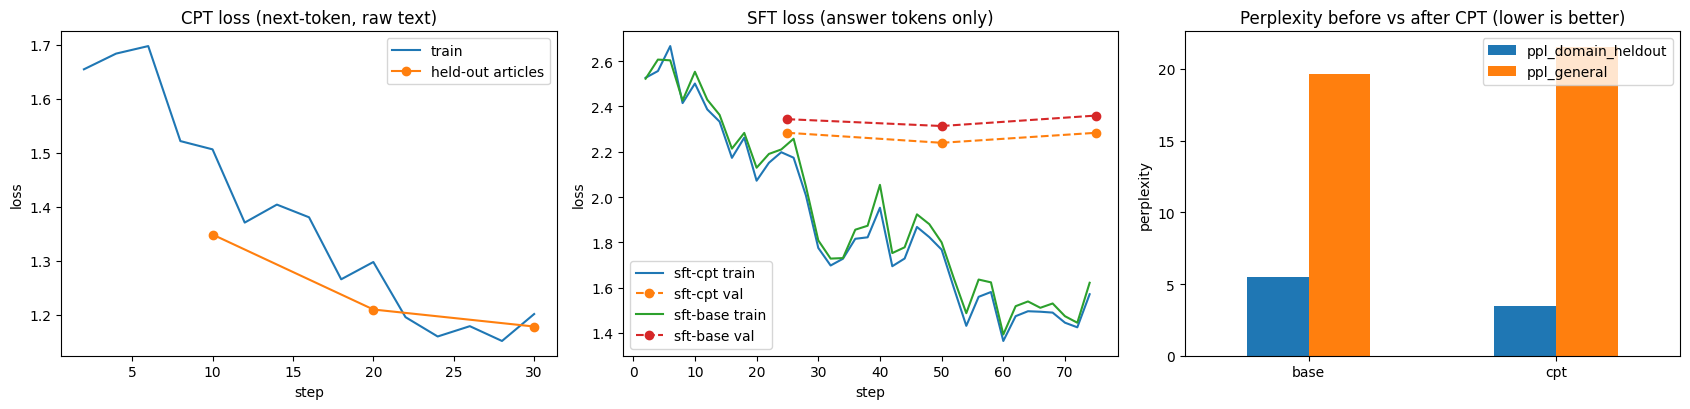

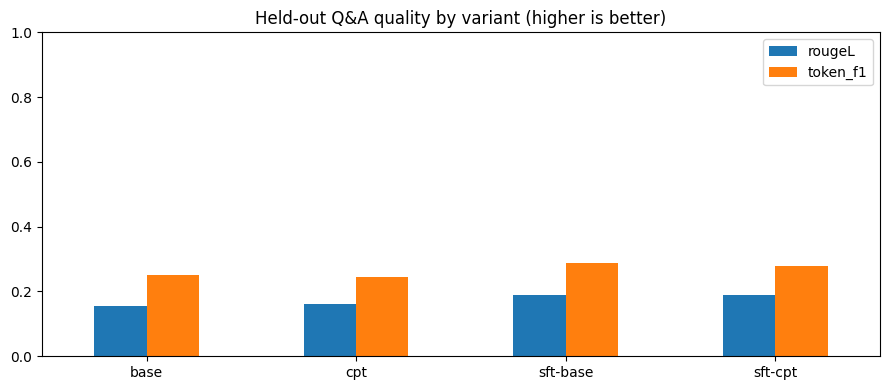

In [35]:
import matplotlib.pyplot as plt

def curves(log):
    tr = [(e["step"], e["loss"]) for e in log if "loss" in e]
    ev = [(e["step"], e["eval_loss"]) for e in log if "eval_loss" in e]
    return tr, ev

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
tr, ev = curves(cpt_log)
axes[0].plot(*zip(*tr), label="train"); axes[0].plot(*zip(*ev), "o-", label="held-out articles")
axes[0].set(title="CPT loss (next-token, raw text)", xlabel="step", ylabel="loss"); axes[0].legend()
for tag, log in sft_logs.items():
    tr, ev = curves(log)
    axes[1].plot(*zip(*tr), label=f"sft-{tag} train")
    axes[1].plot(*zip(*ev), "o--", label=f"sft-{tag} val")
axes[1].set(title="SFT loss (answer tokens only)", xlabel="step", ylabel="loss"); axes[1].legend()
ppl = summary[["ppl_domain_heldout", "ppl_general"]].loc[["base", "cpt"]]
ppl.plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Perplexity before vs after CPT (lower is better)", ylabel="perplexity")
plt.tight_layout(); plt.savefig("results_training.png", dpi=130); plt.show()

metric_cols = [c for c in ["rougeL", "token_f1", "judge_correct_rate"] if c in summary.columns]
ax = summary[metric_cols].plot.bar(rot=0, figsize=(9, 4), title="Held-out Q&A quality by variant (higher is better)")
ax.set_ylim(0, 1); plt.tight_layout(); plt.savefig("results_qa.png", dpi=130); plt.show()

### Side-by-side answers
Numbers summarise; examples show *how* the variants differ. Look for: does `base`/`cpt` answer at all or
ramble? Does SFT produce the right *shape*? Does CPT → SFT get more of the *facts* right than SFT alone?

In [38]:
judgements = {}

for i in random.Random(1).sample(range(len(eval_set)), min(6, len(eval_set))):
    p = eval_set[i]
    print("═" * 100 + f"\n[{p['question_type']} | {p['source_section']}] {p['instruction']}\n")
    print(f"REFERENCE: {p['response']}\n")
    for name in order:
        g = generations[name][i]
        j = judgements[name][i] if judgements.get(name) else None
        tag = f" (judge {j['score']}/5)" if j else ""
        print(f"{name.upper():9s}{tag}: {g['answer'][:600]}\n")

════════════════════════════════════════════════════════════════════════════════════════════════════
[comparative | Article 66] How does the election of the Vice-President differ from that of the President?

REFERENCE: The President is chosen by elected MPs and elected members of State Assemblies. The Vice-President is elected only by members of both Houses of Parliament, including nominated members, using proportional representation by single transferable vote; State legislators play no part, and the minimum age is thirty-five years for both offices.

BASE     : The election of the Vice-President differs significantly from that of the President under Article 143 of the Indian Constitution. The Vice-President is elected by a majority vote of members of the Lok Sabha, whereas the President is elected indirectly through a two-thirds majority of the total number of members of both Houses of Parliament. This means that the Vice-President's selection process involves more direct participati

In [39]:
by_type = defaultdict(dict)
for name in order:
    for qt in sorted({p["question_type"] for p in eval_set}):
        idx = [i for i, p in enumerate(eval_set) if p["question_type"] == qt]
        if judgements.get(name):
            vals = [judgements[name][i]["score"] for i in idx if judgements[name][i]]
        else:
            vals = [rouge_l(generations[name][i]["answer"], eval_set[i]["response"]) for i in idx]
        by_type[qt][name] = sum(vals) / len(vals) if vals else float("nan")
print("Per question type —", "judge score (1–5)" if judgements else "ROUGE-L")
pd.DataFrame(by_type).T[order].round(3)

Per question type — ROUGE-L


,base,cpt,sft-base,sft-cpt
comparative,0.189,0.179,0.203,0.202
definitional,0.147,0.158,0.205,0.161
explanatory,0.130,0.141,0.161,0.170
factual,0.159,0.168,0.196,0.220
procedural,0.149,0.172,0.224,0.150
scenario,0.179,0.127,0.147,0.137


### Save everything for the report

In [40]:
Path("results").mkdir(exist_ok=True)
summary.to_csv("results/summary.csv")
with open("results/generations.jsonl", "w") as f:
    for i, p in enumerate(eval_set):
        row = {"id": p["id"], "question_type": p["question_type"], "source_section": p["source_section"],
               "question": p["instruction"], "reference": p["response"]}
        for name in order:
            row[name] = generations[name][i]["answer"]
            if judgements.get(name):
                row[f"{name}_judge"] = judgements[name][i]
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
json.dump({"model": MODEL_ID, "results": results, "cpt_log": cpt_log, "sft_logs": sft_logs},
          open("results/metrics.json", "w"), indent=1, default=str)
print(summary.round(3).to_string())

          ppl_domain_heldout  ppl_general  rougeL  token_f1  avg_words  stop_rate
base                   5.458       19.647   0.156     0.250     98.744      0.641
cpt                    3.454       21.548   0.160     0.245     82.205      0.718
sft-base                 NaN          NaN   0.188     0.287     45.795      1.000
sft-cpt                  NaN          NaN   0.190     0.280     47.667      1.000


### Try it yourself

In [41]:
chat_model = PeftModel.from_pretrained(load_model(CPT_MERGED_DIR), SFT_ADAPTER_DIR["cpt"])
def ask(question):
    return generate_answers(chat_model, [question], batch_size=1)[0]["answer"]

for q in ["Who appoints the Chief Election Commissioner and how can they be removed?",
          "What is the difference between a Money Bill and an ordinary Bill?"]:
    print(f"Q: {q}\nA: {ask(q)}\n")

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Q: Who appoints the Chief Election Commissioner and how can they be removed?
A: Article 324 allows the President to appoint a person who is qualified for office as Chief Election Commissioner, with or without remuneration. The Commission must be removed by a resolution passed by two-thirds of the total membership of all State and Union territories, and dismissed if it fails to perform its duties satisfactorily.

Q: What is the difference between a Money Bill and an ordinary Bill?
A: Under Article 110, only Bills dealing with matters such as taxation, public finance and money-lending can be introduced in the House of the People. The Council of States may then pass them by resolution, which takes effect after two weeks' notice.



### Download artefacts
Adapters are small (tens of MB); the merged CPT model is a full copy of the base weights (~3.5 GB for 1.7B),
so it is left out of the zip.

In [42]:
import shutil
bundle = Path("constitution_llm_outputs"); bundle.mkdir(exist_ok=True)
for src in ["results", "data", str(CPT_ADAPTER_DIR), *map(str, SFT_ADAPTER_DIR.values()),
            "results_training.png", "results_qa.png"]:
    if Path(src).exists():
        dst = bundle / Path(src).name
        shutil.copytree(src, dst, dirs_exist_ok=True) if Path(src).is_dir() else shutil.copy(src, dst)
shutil.make_archive("constitution_llm_outputs", "zip", bundle)
try:
    from google.colab import files
    files.download("constitution_llm_outputs.zip")
except Exception:
    print("saved constitution_llm_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

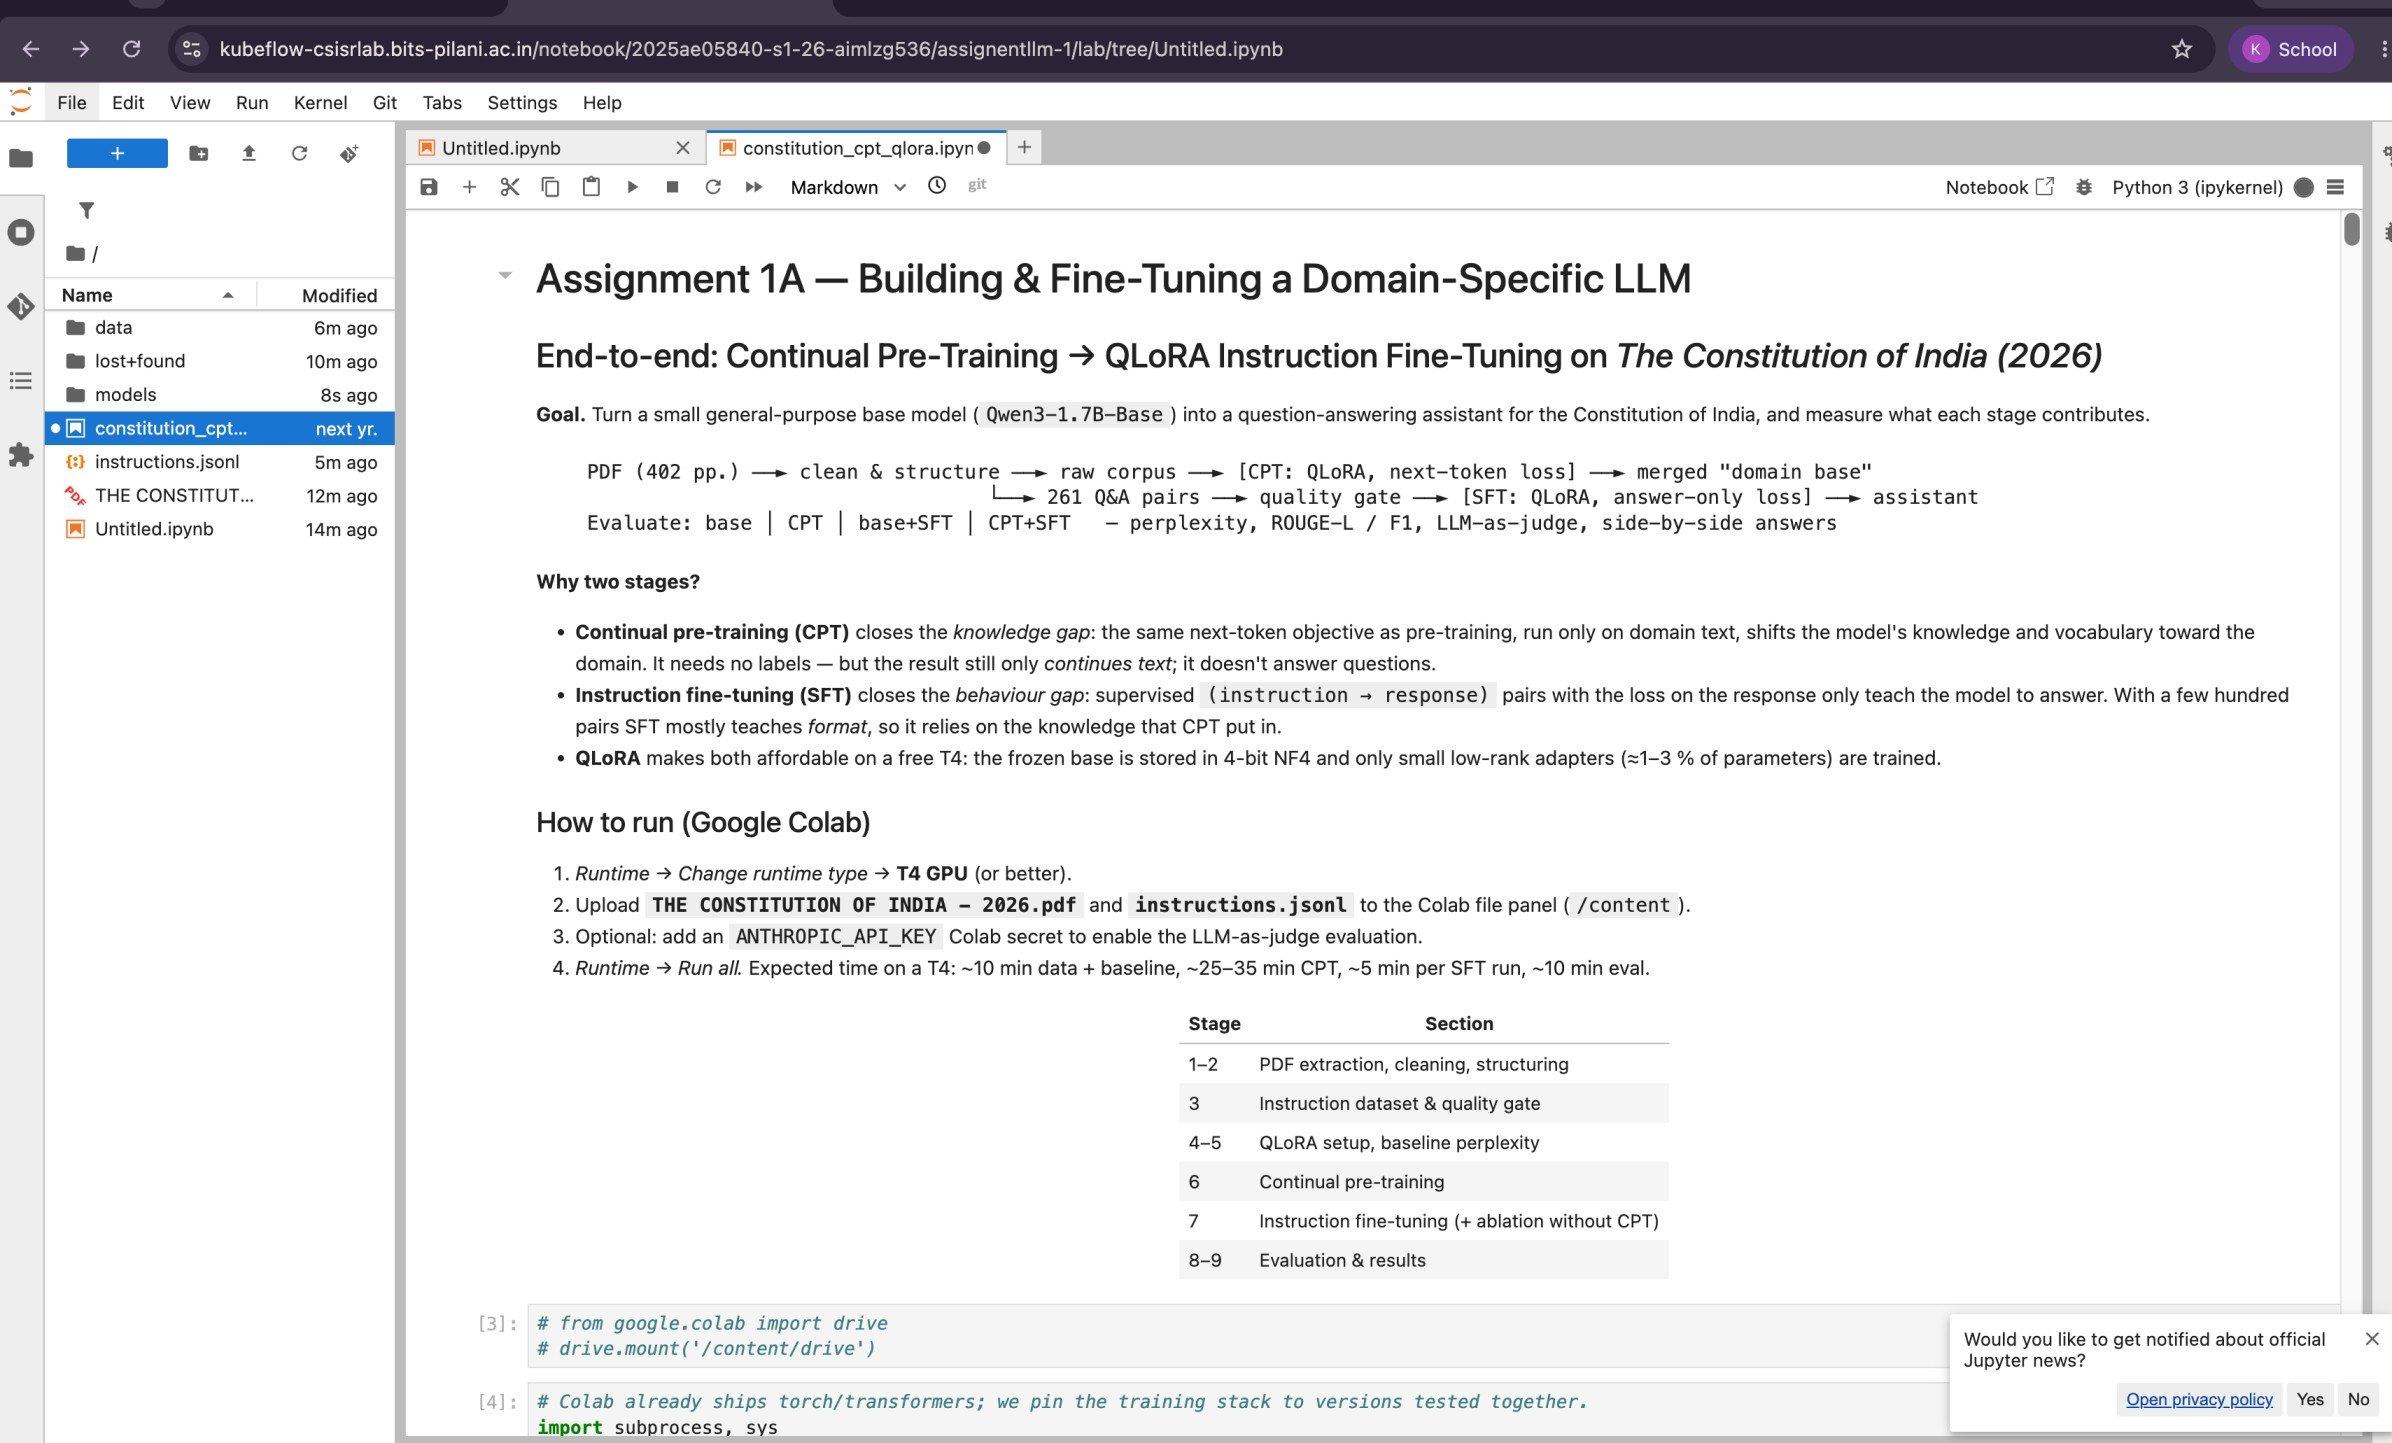

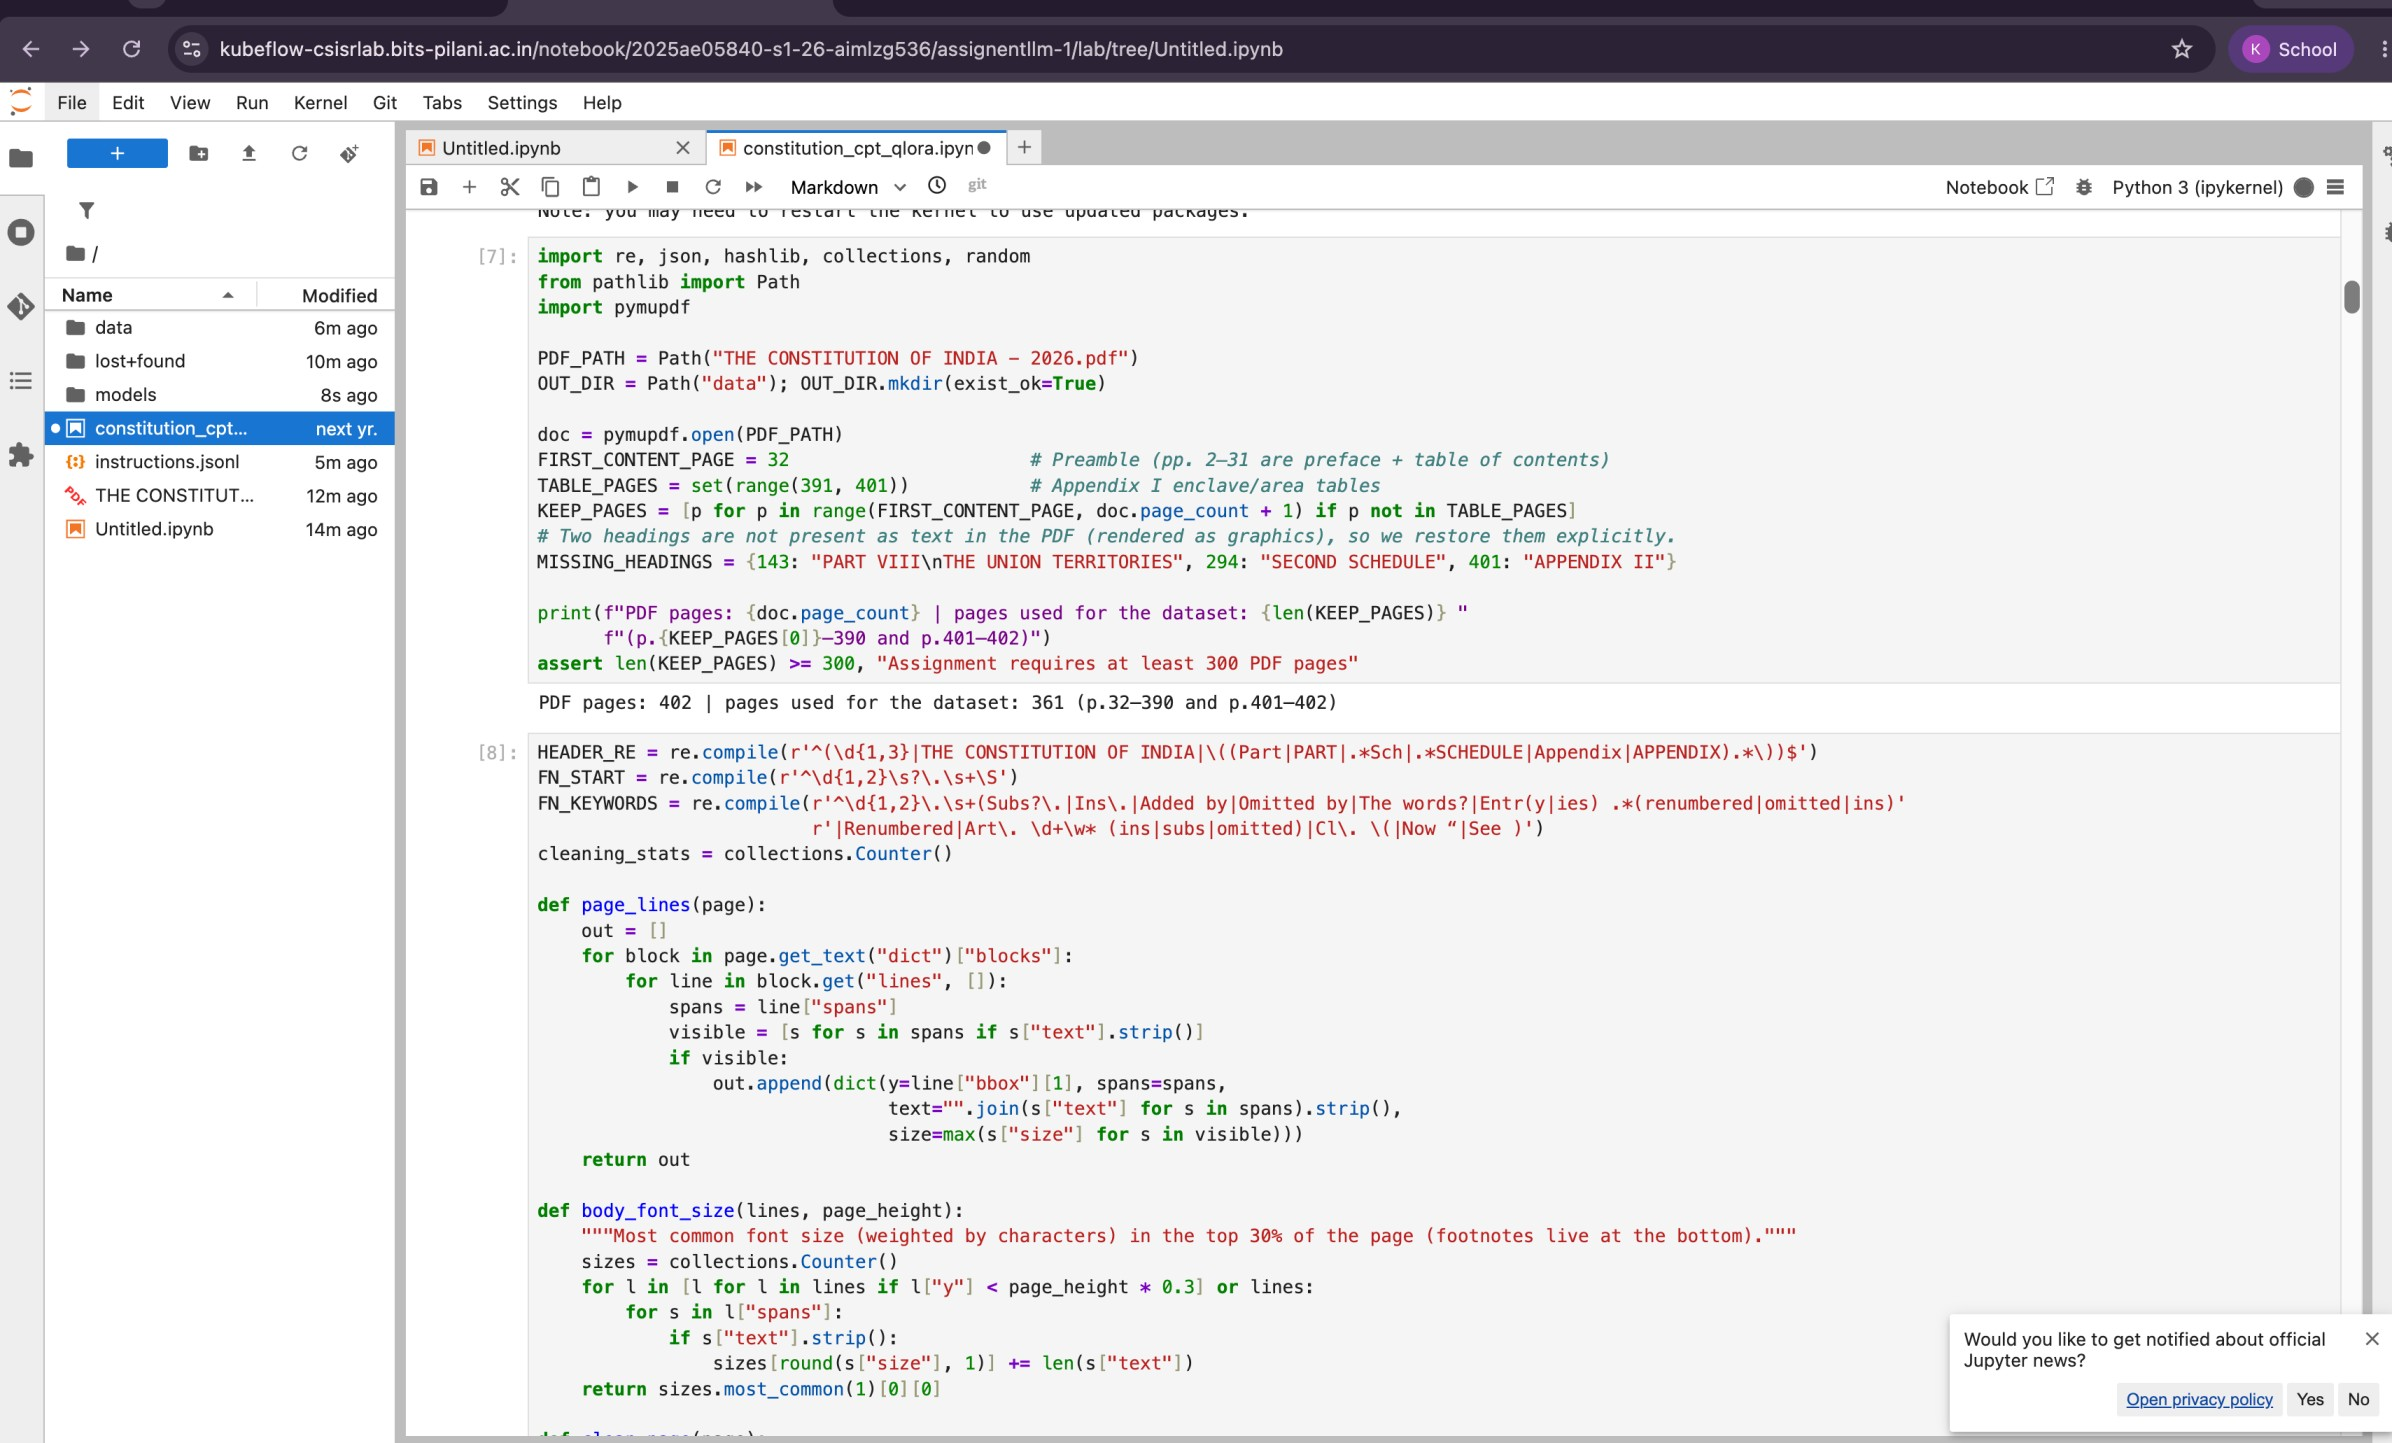

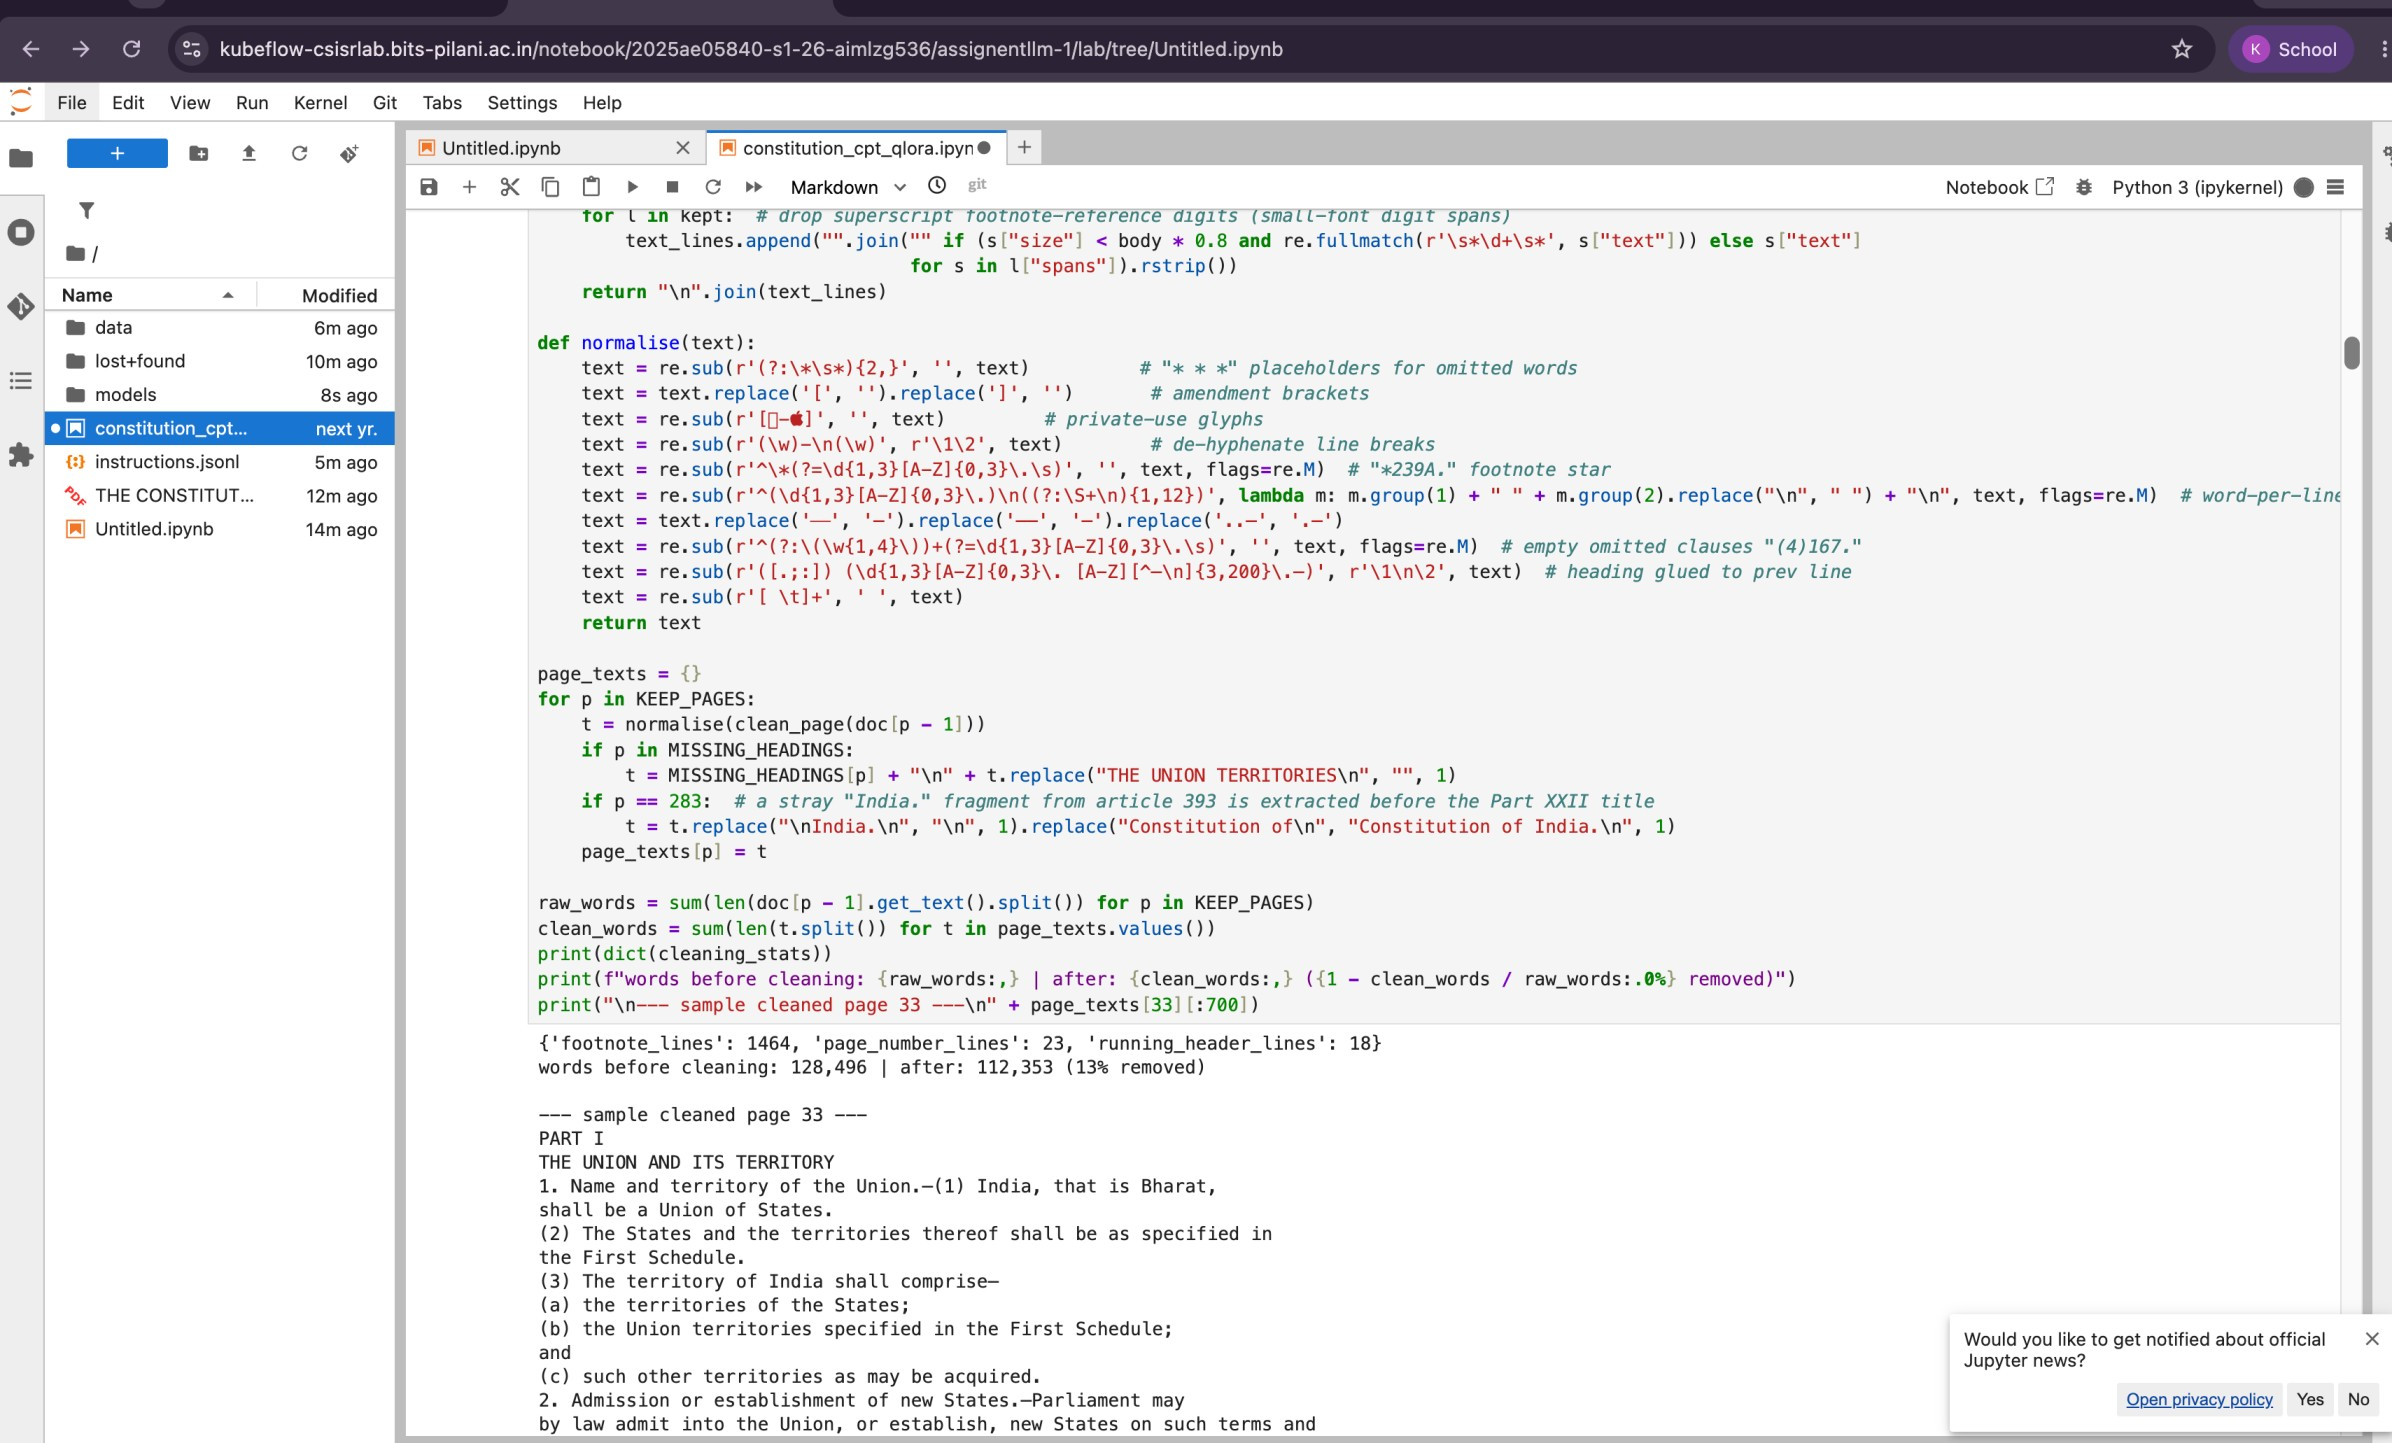

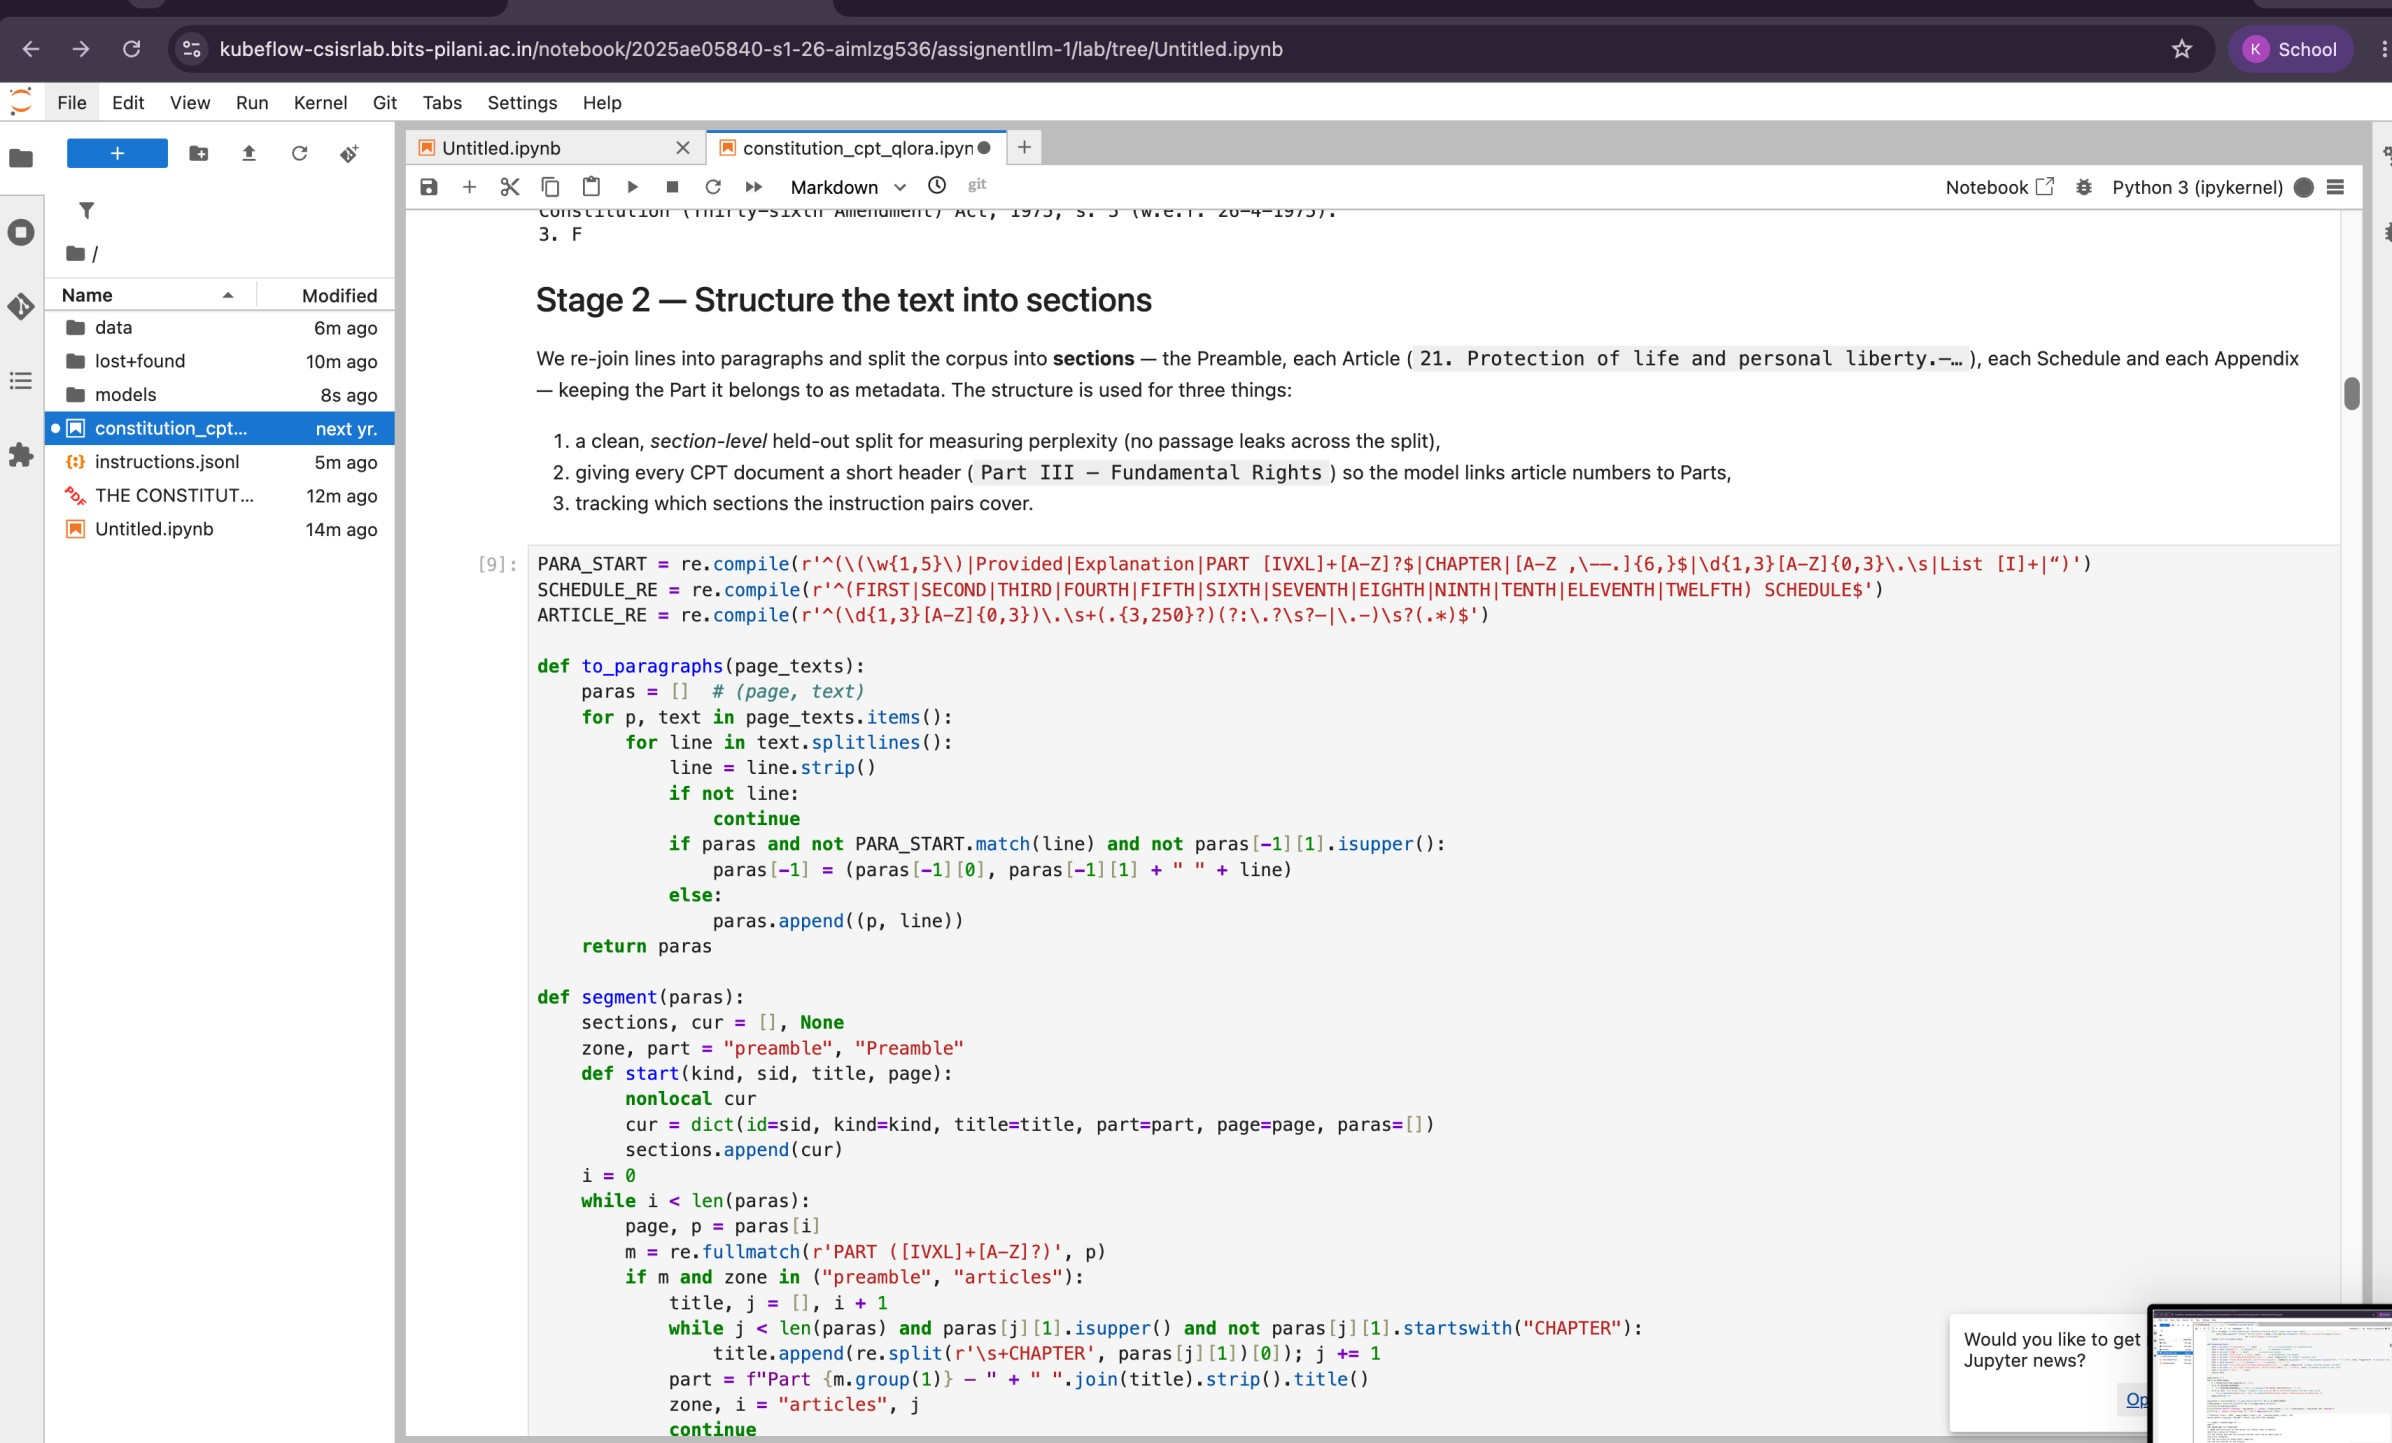

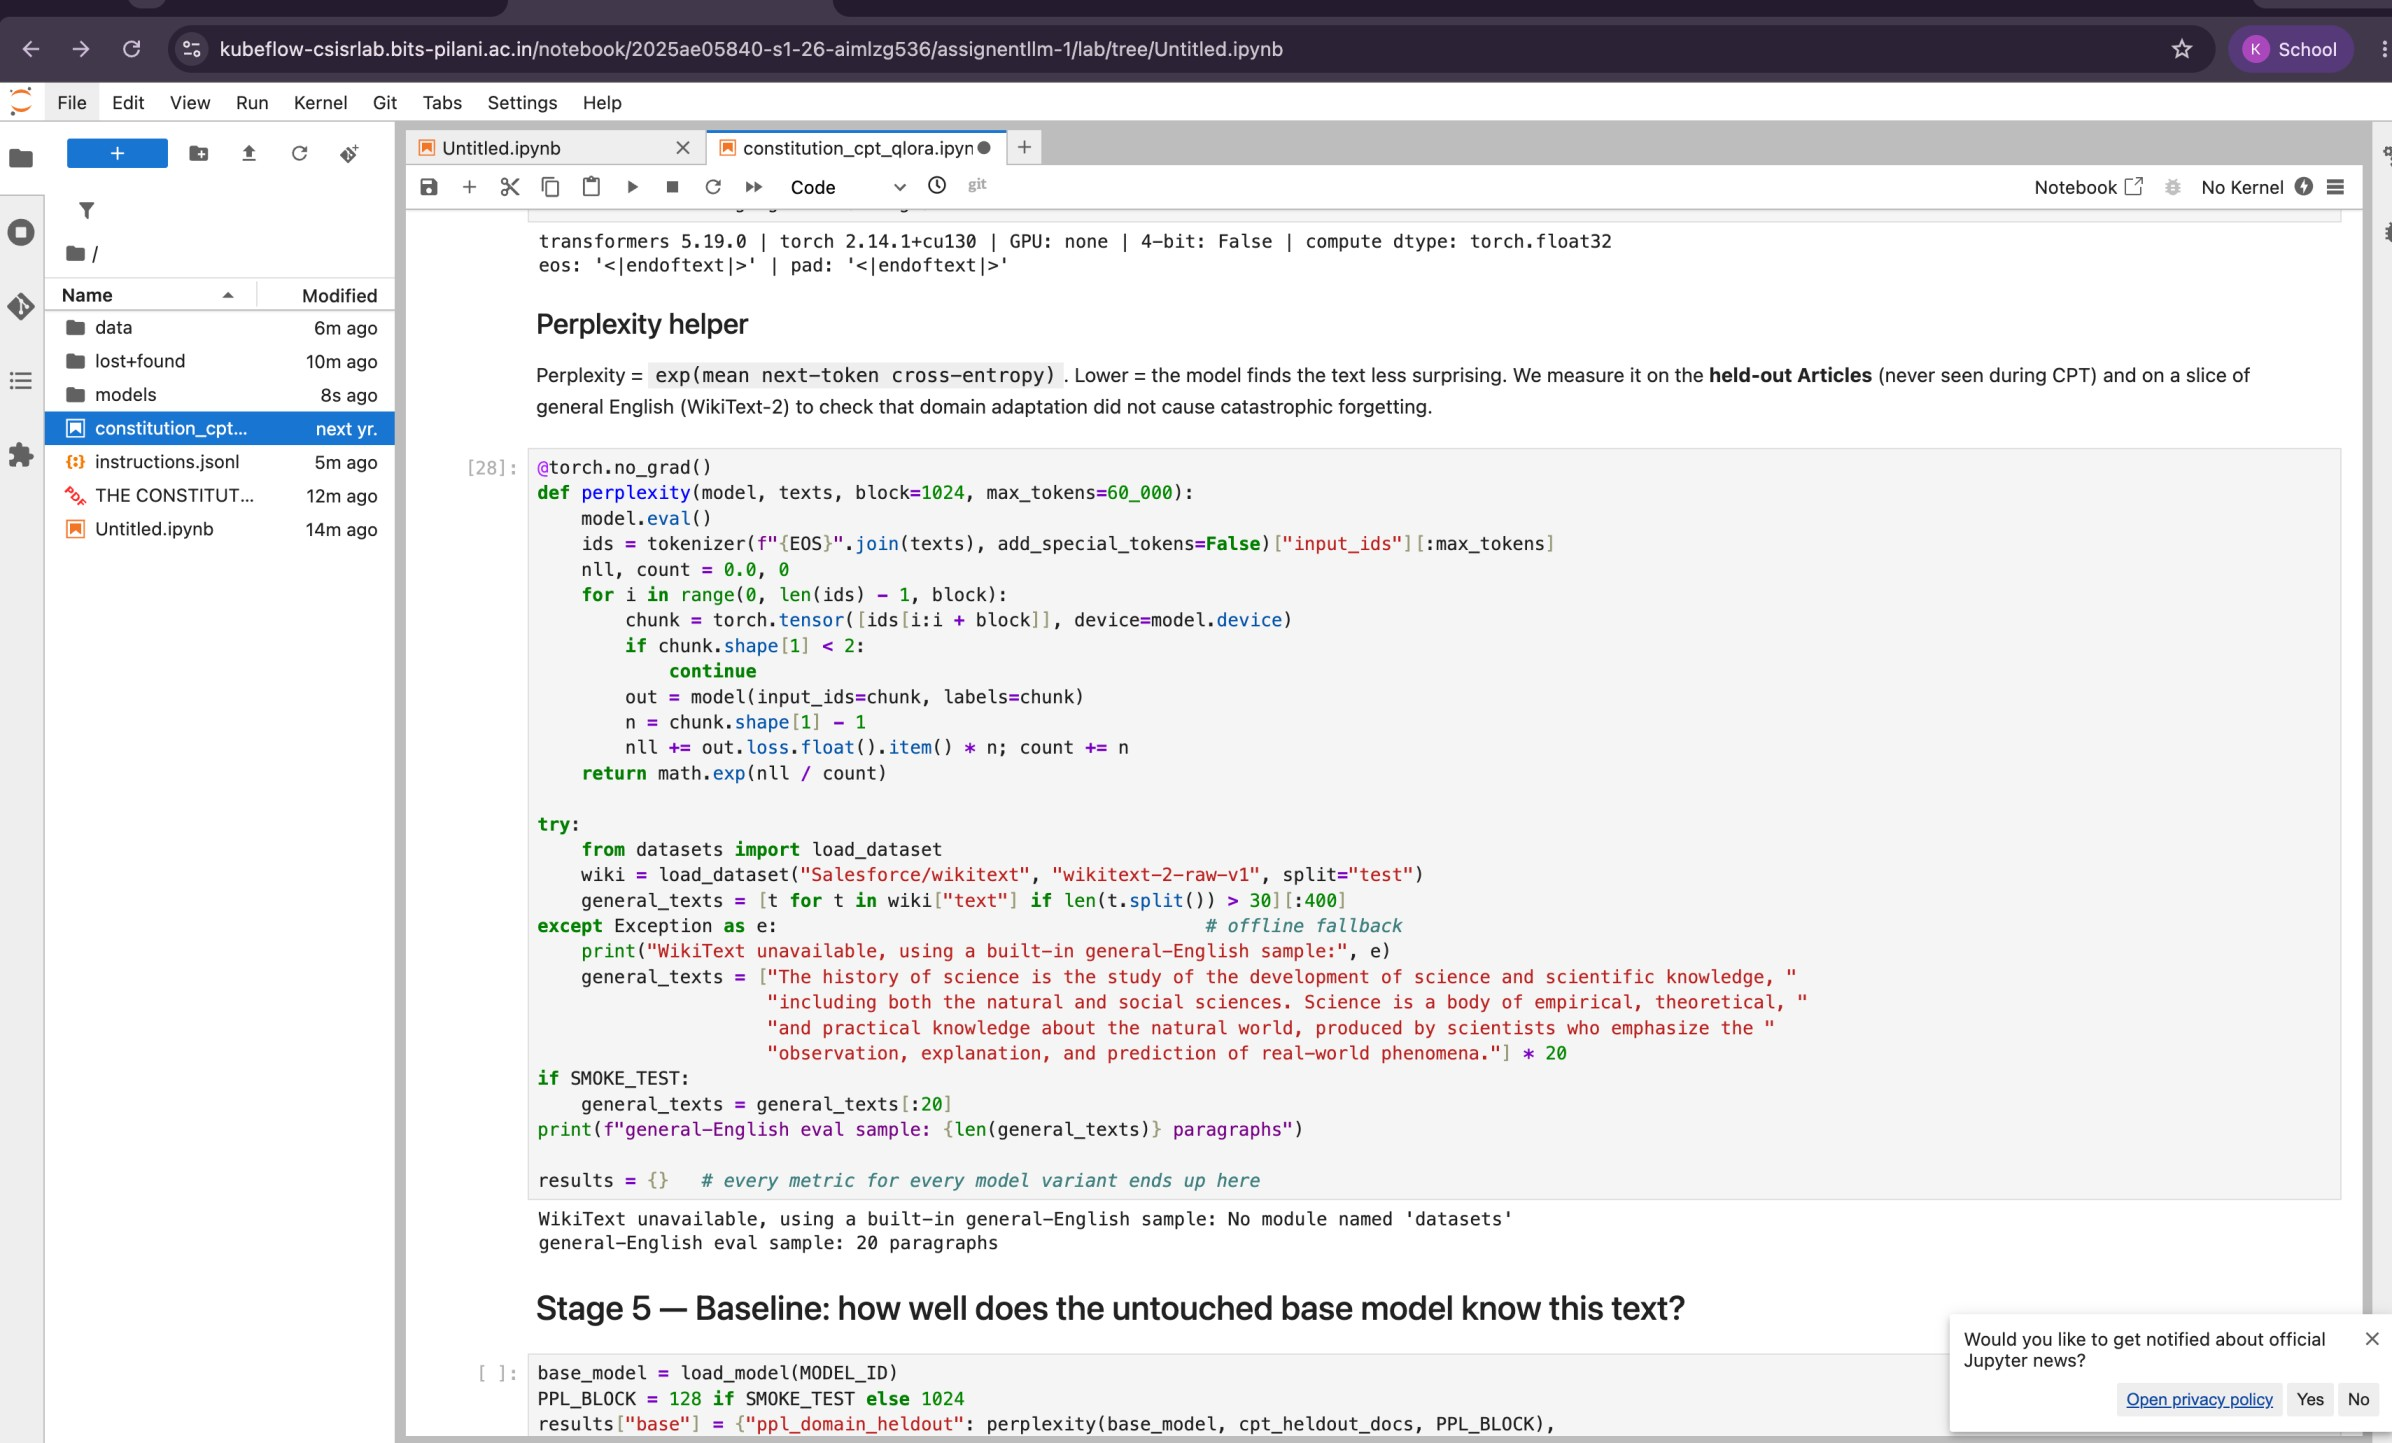